# RQ7.2: the laboratory-to-field gap (COS 801, PJT07, Group 6)

> *How large is the performance drop between laboratory-condition training images
> and field-condition test images, and which augmentation strategies reduce it most?*

Train on PlantVillage only. Score every model on held-out PlantVillage (`lab_test`)
and on the PlantDoc test split (`field_test`), with the same classes and metric.

* **Claim 1, the gap:** the control arm A0 (minimal augmentation) gives
  lab macro-F1 minus field macro-F1, with a bootstrap interval.
* **Claim 2, what reduces it:** arms A1 to A4 differ from A0 in augmentation only.
  Each is compared with A0 by a paired bootstrap on the same field images,
  averaged over three seeds.

**Runs on both Colab and VS Code from this one file.**

| Where | How |
|---|---|
| VS Code, as a script | `python rq72.py check`, then `preview`, `train`, `analyse` |
| An existing .pth | `python rq72.py inspect --ckpt model.pth`, then `evaluate --ckpt model.pth` |
| VS Code, interactively | run the `# %%` cells (Jupyter extension) |
| Colab | open `rq72.ipynb`, or `!python rq72.py train` from a cell after mounting Drive |

**Workflow:** `check` (read the printout), `preview` (look at fig0),
`train --smoke` (1 to 2 minutes), `train` (the real sweep), `analyse`.
The sweep resumes after a Colab disconnect: rerun the same command.

Requirements: torch, torchvision, numpy, pandas, pillow, matplotlib.
All of these are preinstalled on Colab.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Setup

**Colab:** use a GPU runtime (Runtime → Change runtime type → T4 GPU), then run this cell to mount Drive. Results are written to the shared drive, so a disconnect loses at most one epoch. Rerun every cell, including the sweep cell, and it resumes.

**VS Code:** nothing to mount. If the data isn't under the folder you opened, set the `RQ72_ROOT` environment variable or `CONFIG['local_root']` below.

In [2]:
import os
if "COLAB_RELEASE_TAG" in os.environ:
    from google.colab import drive
    drive.mount("/content/drive")
    !nvidia-smi --query-gpu=name,memory.total --format=csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [3]:
from __future__ import annotations

import argparse
import ast
import copy
import hashlib
import io
import json
import math
import os
import random
import shutil
import sys
import time
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFilter

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import torchvision
import torchvision.transforms as T

## 1. Configuration

**A0 is the group baseline.** The settings below copy the two baseline notebooks
(`COS801_mobilenetv3_baselinemodel` and `EfficientNetB0_Baseline_Training`):
the same split CSV, class order, ImageNet-pretrained backbone, 224 px input,
training augmentation, AdamW at 1e-3 with weight decay 1e-4 and a cosine schedule,
batch 32, uniform shuffling, full precision, deterministic cuDNN, seed 42, and the
best epoch chosen on validation accuracy. Epochs depend on the backbone
(`BASELINE_RECIPES`: 10 for MobileNetV3-Small, 5 for EfficientNet-B0).

So A0 *is* the group baseline, retrained with three seeds, and the arms differ from it
in training augmentation only. RQ7.2 adds to it, without changing it:
macro-F1 and calibration on top of accuracy, three seeds, and
paired confidence intervals.

Two deliberate differences remain. Images are cached locally for speed; PlantVillage
files are copied byte for byte, while large PlantDoc photos are downscaled to 320 px
before the same 224 px resize. And unreadable images are dropped with a warning
instead of being silently replaced by a random other image.

In [4]:
CONFIG = {
    # where things live
    "colab_root": "/content/drive/Shareddrives/COS 801 Group 6",
    "local_root": os.environ.get("RQ72_ROOT", str(Path.cwd())),
    "manifest": None,           # split CSV, relative to root. None = auto-find under <root>/data
    "results_dir": "results/rq72_aligned",  # relative to root, so on Colab it is on Drive and survives disconnects
    "cache_dir": None,          # None = /content/rq72_cache_v2 on Colab, <root>/cache/rq72_v2 locally
    "cache_images": True,       # downsized local copies; Drive reads are far too slow to train from
    "cache_max_side": 320,      # only ever downscales; every arm and both test sets see the same cache
    "cache_archive": True,      # Colab only: keep a zip of the cache on Drive and unzip it each session

    # manifest columns. None = auto-detect, and `check` prints what it found
    "path_col": "path",
    "label_col": None,
    "split_col": None,
    "domain_col": None,
    "group_col": None,          # near-duplicate group id, if the manifest has one

    # THE GROUP'S BASELINE RECIPE (COS801_mobilenetv3_baselinemodel / EfficientNetB0_Baseline_Training)
    # A0 is trained exactly this way, so it is the group baseline; the arms change the augmentation only.
    "backbone": "mobilenet_v3_small",  # copied from the teammate's checkpoint in the notebook
    "pretrained": True,         # ImageNet weights, as in both baseline notebooks
    "pretrained_path": None,    # local ImageNet .pth, if downloading weights fails; see section 9
    "img_size": 224,
    "epochs": 10,               # MobileNetV3-Small baseline: 10; EfficientNet-B0 baseline: 5 (BASELINE_RECIPES)
    "batch_size": 32,
    "lr": 1e-3,                 # AdamW, cosine schedule over all epochs
    "weight_decay": 1e-4,
    "label_smoothing": 0.0,
    "balanced_sampling": False, # baselines shuffle uniformly; True draws classes equally instead
    "a0_rotation": 10,          # baselines: Resize, RandomHorizontalFlip, RandomRotation(10) with black fill
    "select_metric": "accuracy",  # baselines keep the epoch with the best validation accuracy
    "deterministic": True,      # baselines set cudnn.deterministic=True, benchmark=False
    "class_order": [            # the group's canonical label order (shared_class_labels.py, SHARED_CLASSES)
        "apple_scab", "apple_rust", "apple_healthy", "blueberry_healthy", "cherry_healthy",
        "corn_gray_spot", "corn_rust", "corn_blight", "grape_black_rot", "grape_healthy",
        "peach_healthy", "pepper_healthy", "potato_early_blight", "potato_late_blight",
        "raspberry_healthy", "soybean_healthy", "squash_mildew", "strawberry_healthy",
        "tomato_bacterial_spot", "tomato_early_blight", "tomato_late_blight", "tomato_leaf_mold",
        "tomato_septoria", "tomato_yellow_virus", "tomato_mosaic_virus", "tomato_healthy"],

    # the experiment
    "arms": ["A0_none", "A1_geometric", "A2_photometric", "A3_degradation", "A4_combined"],
    "seeds": [42, 43, 44],      # 42 is the baselines' seed
    "max_lab_train_per_class": None,  # e.g. 400 to shorten runs; applied identically to every arm
    "time_budget_h": None,      # stop starting new runs once the next one would overrun this; rerun to continue
    "drop_field_conflicts": False, # True removes the 11 PlantDoc images filed under two diseases (see section 3).
                                   # False keeps the group's 2,499-image field test set.
    "num_workers": None,        # None = chosen per platform
    "use_amp": False,           # the baselines train in full precision

    # analysis
    "n_boot": 2000,
    "ece_bins": 15,
    "smoke": False,
}

# Per-backbone settings from the two baseline notebooks; everything else is shared and lives in CONFIG.
BASELINE_RECIPES = {
    "mobilenet_v3_small": {"epochs": 10},
    "efficientnet_b0": {"epochs": 5},
}

SMOKE_OVERRIDES = {
    "arms": ["A0_none", "A4_combined"],
    "seeds": [42],
    "epochs": 1,
    "max_lab_train_per_class": 16,
    "max_eval_per_split": 200,
    "results_dir": "results/rq72_smoke_aligned",
    "n_boot": 200,
    "smoke": True,
}


def make_config(smoke: bool = False, **overrides) -> dict:
    cfg = copy.deepcopy(CONFIG)
    if smoke:
        cfg.update(SMOKE_OVERRIDES)
    cfg.update(overrides)
    return cfg

## 2. Environment: Colab or local, and which device

In [ ]:
def _in_notebook() -> bool:
    return "ipykernel" in sys.modules


IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules
IN_NOTEBOOK = _in_notebook()


def get_root(cfg: dict) -> Path:
    if IN_COLAB:
        root = Path(cfg["colab_root"])
        if not root.exists():
            if IN_NOTEBOOK:
                from google.colab import drive  # type: ignore
                drive.mount("/content/drive")
            if not root.exists():
                raise FileNotFoundError(
                    f"{root} not found. Mount Drive in a notebook cell first:\n"
                    "    from google.colab import drive; drive.mount('/content/drive')\n"
                    "and check that the shared drive is named exactly 'COS 801 Group 6'.")
        return root
    return Path(cfg["local_root"]).expanduser().resolve()


def get_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def default_workers(cfg: dict) -> int:
    if cfg.get("num_workers") is not None:
        return int(cfg["num_workers"])
    if sys.platform == "darwin" and IN_NOTEBOOK:
        return 0  # macOS spawns workers, which cannot import classes defined in notebook cells
    if IN_COLAB:
        return min(8, os.cpu_count() or 2)  # Colab has few CPUs and image decoding is the bottleneck
    return min(8, max(0, (os.cpu_count() or 2) - 1))


def seed_everything(seed: int, deterministic: bool = False) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if deterministic:  # as in the baseline notebooks
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def _worker_init(worker_id: int) -> None:
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

## 3. Data: read the group's split CSV and assign each image a role

Every image gets exactly one role:
`lab_train`, `lab_val`, `lab_test`, `field_test`, or `field_unused`.
The PlantDoc train split is `field_unused`. **No arm here ever trains on PlantDoc.**

`check` prints the role counts. Read them before training anything.

In [6]:
LABEL_CANDIDATES = ["label", "canonical", "canonical_class", "class", "class_name", "target"]
SPLIT_CANDIDATES = ["split", "subset", "partition", "set", "role"]
DOMAIN_CANDIDATES = ["domain", "source", "dataset", "origin"]
GROUP_CANDIDATES = ["group", "group_id", "dup_group", "dedup_group"]


def _pick(df: pd.DataFrame, wanted, candidates, what: str, required=True):
    if wanted:
        if wanted not in df.columns:
            raise KeyError(f"{what} column '{wanted}' not in manifest. Columns: {list(df.columns)}")
        return wanted
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(f"Could not find a {what} column. Columns: {list(df.columns)}. "
                       f"Set CONFIG['{what}_col'].")
    return None


def find_manifest(cfg: dict, root: Path) -> Path:
    if cfg.get("manifest"):
        p = Path(cfg["manifest"])
        p = p if p.is_absolute() else root / p
        if not p.exists():
            raise FileNotFoundError(p)
        return p
    found = []
    for base in [root / "data", root]:
        if base.is_dir():
            # shallow search only: a recursive glob would walk every image folder on Drive
            for f in sorted(list(base.glob("*.csv")) + list(base.glob("*/*.csv"))):
                if "results" in f.parts or "cache" in f.parts or f.name == "path_diagnosis.csv":
                    continue
                try:
                    cols = pd.read_csv(f, nrows=2).columns
                except Exception:
                    continue
                if cfg["path_col"] in cols:
                    found.append(f)
        if found:
            break
    if len(found) == 1:
        return found[0]
    resolved = [f for f in found if f.name.endswith("_resolved.csv")]
    if len(resolved) == 1:  # written by diagnose_paths.py: same rows and splits, corrected file names
        return resolved[0]
    preferred = [f for f in found if any(k in f.name.lower() for k in ("manifest", "split"))]
    if len(preferred) == 1:
        return preferred[0]
    if not found:
        raise FileNotFoundError(
            f"No CSV with a '{cfg['path_col']}' column under {root}/data. Set CONFIG['manifest'].")
    raise RuntimeError("Several candidate manifests found; set CONFIG['manifest'] to one of:\n  "
                       + "\n  ".join(str(f) for f in found))


def _domain(value: str) -> str | None:
    v = str(value).lower().replace(" ", "").replace("-", "").replace("_", "")
    if "plantdoc" in v or v == "field":
        return "field"
    if "plantvillage" in v or "village" in v or v == "lab":
        return "lab"
    return None


def _split(value: str) -> str | None:
    v = str(value).lower().strip()
    for prefix in ("lab_", "field_"):
        if v.startswith(prefix):
            v = v[len(prefix):]
    if v in {"train", "training", "tr"}:
        return "train"
    if v in {"val", "valid", "validation", "dev"}:
        return "val"
    if v in {"test", "testing", "te", "holdout"}:
        return "test"
    if v in {"unlabelled", "unlabeled", "unused"}:
        return "train"
    return None


def assign_roles(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    df = df.copy()
    pcol = cfg["path_col"]
    lcol = _pick(df, cfg["label_col"], LABEL_CANDIDATES, "label")
    scol = _pick(df, cfg["split_col"], SPLIT_CANDIDATES, "split")
    dcol = _pick(df, cfg["domain_col"], DOMAIN_CANDIDATES, "domain", required=False)
    gcol = _pick(df, cfg["group_col"], GROUP_CANDIDATES, "group", required=False)

    dom = df[dcol].map(_domain) if dcol else pd.Series([None] * len(df), index=df.index)
    # fall back to the split value ("lab_train") and then to the path ("raw/plantdoc/...")
    dom = dom.fillna(df[scol].map(lambda s: _domain(str(s).split("_")[0])))
    dom = dom.fillna(df[pcol].map(lambda p: next((d for d in map(_domain, Path(str(p)).parts) if d), None)))
    if dom.isna().any():
        bad = df.loc[dom.isna(), pcol].head(5).tolist()
        raise ValueError(f"{int(dom.isna().sum())} rows have no recognisable domain, e.g. {bad}. "
                         "Set CONFIG['domain_col'].")
    spl = df[scol].map(_split)
    if spl.isna().any():
        raise ValueError(f"Unrecognised split values: {sorted(df.loc[spl.isna(), scol].astype(str).unique())[:10]}")

    role = np.where(dom == "lab", "lab_" + spl, np.where(spl == "test", "field_test", "field_unused"))
    df["role"] = role
    df["label"] = df[lcol].astype(str).str.strip()
    df["group"] = df[gcol].astype(str) if gcol else df[pcol].astype(str)
    df.attrs["columns_used"] = {"path": pcol, "label": lcol, "split": scol, "domain": dcol, "group": gcol}

    if not (df.role == "lab_val").any():
        # carve a validation set from lab_train, whole duplicate groups at a time
        rng = np.random.default_rng(0)
        tr = df.index[df.role == "lab_train"]
        for _, sub in df.loc[tr].groupby("label"):
            groups = np.array(sub.group.unique())
            rng.shuffle(groups)
            take = set(groups[: max(1, int(round(0.1 * len(groups))))])
            df.loc[sub.index[sub.group.isin(take)], "role"] = "lab_val"
        df.attrs["carved_val"] = True
    return df


def resolve_paths(df: pd.DataFrame, cfg: dict, root: Path) -> tuple[pd.DataFrame, Path]:
    """CSV paths may be relative to the group root or to <root>/data. Try both."""
    pcol = cfg["path_col"]
    sample = df[pcol].astype(str).sample(min(60, len(df)), random_state=0)
    best, best_hits = None, -1
    for base in [root, root / "data", root.parent, Path("/")]:
        hits = sum((base / p).exists() for p in sample)
        if hits > best_hits:
            best, best_hits = base, hits
    if best_hits == 0:
        raise FileNotFoundError(f"None of the sampled image paths exist, e.g. {root / sample.iloc[0]}")
    df = df.copy()
    rel = df[pcol].astype(str)
    if "resolved_path" in df.columns:  # from diagnose_paths.py: where the file actually is
        rel = df["resolved_path"].where(df["resolved_path"].notna(), rel).astype(str)
    df["src"] = [str(best / p) for p in rel]
    return df, best


def _cache_name(rel: str) -> str:
    return hashlib.sha1(rel.encode()).hexdigest()[:20] + ".jpg"


def _cache_one(args):
    src, dst, max_side = args
    if os.path.exists(dst):
        return True
    try:
        tmp = dst + ".tmp"
        with Image.open(src) as im:
            fmt = im.format
            im.load()  # full decode, so a damaged file fails here rather than mid-training
            if max(im.size) <= max_side and fmt == "JPEG":
                # Small JPEG (all of PlantVillage is 256 px): keep the original bytes, so the pixels are
                # exactly what the baseline notebooks read from Drive.
                shutil.copyfile(src, tmp)
            else:
                im = im.convert("RGB")
                if max(im.size) > max_side:
                    im.thumbnail((max_side, max_side), Image.BILINEAR)
                im.save(tmp, "JPEG", quality=95)
        os.replace(tmp, dst)
        return True
    except Exception:
        return False


def build_cache(df: pd.DataFrame, cfg: dict, root: Path) -> pd.DataFrame:
    df = df.copy()
    if not cfg["cache_images"]:
        df["file"] = df["src"]
        return df
    # v2: PlantVillage originals copied byte for byte (v1 re-encoded them); never mix the two caches.
    cache = Path(cfg["cache_dir"] or ("/content/rq72_cache_v2" if IN_COLAB else root / "cache" / "rq72_v2"))
    cache.mkdir(parents=True, exist_ok=True)
    archive = root / "cache" / f"rq72_cache_v2_{cfg['cache_max_side']}.zip"
    use_archive = IN_COLAB and cfg["cache_archive"]
    if use_archive and archive.exists() and not any(cache.iterdir()):
        print(f"Unpacking image cache from {archive} ...")
        with zipfile.ZipFile(archive) as z:
            z.extractall(cache)

    df["file"] = [str(cache / _cache_name(r)) for r in df[cfg["path_col"]].astype(str)]
    todo = [(s, f, cfg["cache_max_side"]) for s, f in zip(df.src, df.file) if not os.path.exists(f)]
    if todo:
        # Check the sources exist before spending 20+ minutes caching: one listing per folder, fast on Drive.
        listing = {}
        missing = []
        for src, _, _ in todo:
            d, name = os.path.split(src)
            if d not in listing:
                try:
                    listing[d] = set(os.listdir(d))
                except OSError:
                    listing[d] = set()
            if name not in listing[d]:
                missing.append(src)
        if len(missing) / max(1, len(df)) > 0.02:
            by_folder = pd.Series([str(Path(m).parent.relative_to(root)) if str(m).startswith(str(root)) else
                                   str(Path(m).parent) for m in missing]).value_counts()
            raise RuntimeError(
                f"{len(missing)} of {len(df)} images are not on the drive ({100 * len(missing) / len(df):.0f}%), "
                "so training now would use a different split from the CSV. Most affected folders:\n"
                + by_folder.head(8).to_string()
                + "\nFinish the upload (run diagnose_paths.py to see exactly what is missing), then rerun.")
    if todo:
        print(f"Caching {len(todo)} images to {cache} (once per machine; Colab: once per session"
              f"{' unless the zip exists' if use_archive else ''}) ...")
        t0, ok = time.time(), []
        with ThreadPoolExecutor(16) as ex:
            for i, r in enumerate(ex.map(_cache_one, todo), 1):
                ok.append(r)
                if i % 2000 == 0:
                    print(f"  {i}/{len(todo)}  {time.time() - t0:.0f}s")
        failed = len(ok) - sum(ok)
        if failed / max(1, len(df)) > 0.02:
            raise RuntimeError(f"{failed} images failed to read. Above 2% this is a path or upload "
                               "problem, not bad data; fix it before training.")
        if use_archive:
            archive.parent.mkdir(parents=True, exist_ok=True)
            print(f"Writing cache archive to {archive} for later sessions ...")
            tmp = archive.with_suffix(".zip.tmp")
            with zipfile.ZipFile(tmp, "w", zipfile.ZIP_STORED) as z:
                for f in cache.glob("*.jpg"):
                    z.write(f, f.name)
            os.replace(tmp, archive)
    missing = ~df.file.map(os.path.exists)
    if missing.any():
        print(f"WARNING: dropping {int(missing.sum())} unreadable images: "
              f"{df.loc[missing, cfg['path_col']].head(3).tolist()}")
        df = df[~missing]
    return df


def _drop_field_conflicts(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """PlantDoc contains some identical images filed under two different diseases. In the test set they
    guarantee an error whatever the model does, so they are removed. Identical copies with the same label
    are reduced to one. Same filename is only a candidate; identical bytes decide."""
    field = df[df.role.isin(["field_test", "field_unused"])]
    base = field[cfg["path_col"]].astype(str).str.split("/").str[-1]
    cand = field[base.duplicated(keep=False)]
    if cand.empty:
        return df
    digests = {}
    for i, src in zip(cand.index, cand.src):
        try:
            with open(src, "rb") as fh:
                digests[i] = hashlib.md5(fh.read()).hexdigest()
        except OSError:
            pass
    groups = pd.Series(digests).groupby(lambda i: digests[i])
    drop, conflicts, repeats = [], 0, 0
    for _, g in groups:
        idx = list(g.index)
        if len(idx) < 2:
            continue
        if df.loc[idx, "label"].nunique() > 1:
            drop += idx
            conflicts += 1
        else:
            drop += idx[1:]
            repeats += 1
    if drop:
        print(f"Field set: removed {len(drop)} rows: {conflicts} images filed under two different diseases "
              f"(all copies dropped) and {repeats} images listed twice with the same label (one copy kept).")
    return df.drop(index=drop)


def prepare_data(cfg: dict, verbose: bool = True) -> dict:
    root = get_root(cfg)
    mpath = find_manifest(cfg, root)
    raw = pd.read_csv(mpath)
    df = assign_roles(raw, cfg)
    meta = dict(df.attrs)
    df, base = resolve_paths(df, cfg, root)

    present = set(df.loc[df.role == "lab_train", "label"].unique())
    order = cfg.get("class_order")
    if order and present <= set(order):
        classes = [c for c in order if c in present]  # the group's canonical order: indices match the baselines
    else:
        if order:
            print(f"NOTE: labels not in CONFIG['class_order'] ({sorted(present - set(order))[:5]}); using sorted order.")
        classes = sorted(present)
    cidx = {c: i for i, c in enumerate(classes)}
    out_of_space = (df.role != "field_unused") & ~df.label.isin(cidx)
    dropped = df.loc[out_of_space].groupby(["role", "label"]).size()
    df = df[~out_of_space].copy()
    df["y"] = df.label.map(cidx).fillna(-1).astype(int)  # -1 only for field_unused, dropped below

    if cfg.get("drop_field_conflicts", True):
        df = _drop_field_conflicts(df, cfg)

    if (df.role == "field_test").sum() == 0:
        raise ValueError("No field_test images share a label with lab_train. The two datasets must be "
                         "mapped onto the same canonical class names before RQ7.2 can be measured.")

    cap = cfg.get("max_lab_train_per_class")
    if cap:
        keep = []
        rng = np.random.default_rng(0)
        for _, sub in df[df.role == "lab_train"].groupby("y"):
            idx = sub.index.to_numpy().copy()
            rng.shuffle(idx)
            keep.extend(idx[:cap])
        df = df[(df.role != "lab_train") | df.index.isin(keep)]
    ecap = cfg.get("max_eval_per_split")
    if ecap:
        for r in ("lab_val", "lab_test", "field_test"):
            idx = df.index[df.role == r]
            if len(idx) > ecap:
                df = df.drop(idx[ecap:])

    df = build_cache(df[df.role != "field_unused"], cfg, root)
    df = df.sort_values(["role", cfg["path_col"]]).reset_index(drop=True)

    counts = df.groupby(["label", "role"]).size().unstack(fill_value=0)
    # Folder names -> CSV class, so a checkpoint whose classes are folder names maps exactly, not by guesswork.
    parent = df[cfg["path_col"]].astype(str).map(lambda s: Path(s).parent.name)
    pairs = pd.DataFrame({"folder": parent, "label": df.label}).drop_duplicates()
    unique = pairs.groupby("folder").label.nunique() == 1
    folder_map = {_norm_name(f): l for f, l in zip(pairs.folder, pairs.label) if unique[f]}
    lab_rows = df[df.role.str.startswith("lab_")]
    label_folder = dict(zip(lab_rows.label, lab_rows[cfg["path_col"]].astype(str).map(lambda s: Path(s).parent.name)))
    lab_dirs = None
    try:  # every class folder next to the lab ones: what torchvision ImageFolder would have seen
        top = Path(lab_rows.src.iloc[0]).parent.parent
        lab_dirs = sorted(e.name for e in os.scandir(top) if e.is_dir())
    except (OSError, IndexError, AttributeError):
        pass
    data = {"df": df, "classes": classes, "root": root, "manifest": mpath, "counts": counts, "meta": meta,
            "folder_map": folder_map, "label_folder": label_folder, "lab_dirs": lab_dirs}
    if verbose:
        _print_check(data, raw, base, dropped)
    return data


def _print_check(data, raw, base, dropped):
    df = data["df"]
    print(f"Manifest:      {data['manifest']}  ({len(raw)} rows)")
    print(f"Columns used:  {data['meta'].get('columns_used')}")
    print(f"Images under:  {base}")
    print(f"Device:        {get_device()}   Colab: {IN_COLAB}   notebook: {IN_NOTEBOOK}")
    if data["meta"].get("carved_val"):
        print("NOTE: the manifest has no lab validation split; 10% of lab_train was carved off "
              "by duplicate group. Better: ask for the frozen val split used by the baseline.")
    print("\nImages per role:")
    print(df.role.value_counts().to_string())
    print(f"\n{len(data['classes'])} classes in the shared label space.")
    c = data["counts"]
    thin = c[c.get("field_test", 0) < 15].index.tolist() if "field_test" in c else []
    if thin:
        print(f"Classes with <15 field_test images (per-class F1 is noisy): {thin}")
    empty = [r for r in ("lab_val", "lab_test", "field_test") if r in c and (c[r] == 0).any()]
    for r in empty:
        print(f"WARNING: classes with no {r} images: {c.index[c[r] == 0].tolist()}")
    if len(dropped):
        print("\nDropped (label not in lab_train):")
        print(dropped.to_string())
    print("\nPer-class counts:")
    print(c.to_string())

## 4. The augmentation arms: the independent variable

Each arm is a claim about which nuisance factor differs between lab and field.
A4 is exactly A1 + A2 + A3, so it answers whether the factors add up.

**A0 is the baselines' training transform, verbatim:** resize, horizontal flip and a
rotation of up to 10 degrees with black fill. A2 and A3 each add one factor on top of A0.
A1 replaces A0's small rotation with stronger geometry.

Order matters in A1. Rotation and shear run **before** the crop, filled with each
image's own border colour so the corners match the PlantVillage sheet. Rotating after a
crop leaves large black corner wedges, a constant cue present in lab training images and
absent in field ones. A0's 10-degree rotation leaves only thin black slivers, which are
kept because they are part of the baseline being reproduced. **Check fig0: A0, A2 and A3
may show thin black corners; A1 and A4 should show none.**

Evaluation uses one fixed transform for every arm and every split, and no
test-time augmentation.

In [ ]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
GREY = (128, 128, 128)

ARM_HYPOTHESES = {
    "A0_none": "Control: the group baseline's augmentation (resize, horizontal flip, rotation up to 10 degrees).",
    "A1_geometric": "Field photos differ in framing, scale, angle and leaf orientation.",
    "A2_photometric": "Field photos differ in illumination: colour cast, tone curve and canopy shadow.",
    "A3_degradation": "Phone cameras lose lesion detail: fewer pixels, blur, JPEG artefacts and sensor noise.",
    "A4_combined": "The factors are complementary: A1 + A2 + A3 together.",
}


class RandomGamma:
    def __init__(self, p=0.5, lo=0.6, hi=1.6):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        g = math.exp(random.uniform(math.log(self.lo), math.log(self.hi)))
        lut = [min(255, int(255 * (i / 255) ** g + 0.5)) for i in range(256)]
        return img.point(lut * len(img.getbands()))


class RandomShadow:
    """A soft dark polygon: canopy leaves shading each other."""

    def __init__(self, p=0.4, strength=(0.45, 0.8)):
        self.p, self.strength = p, strength

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        cx, cy = random.uniform(0, w), random.uniform(0, h)
        r = random.uniform(0.25, 0.6) * max(w, h)
        pts = [(cx + r * random.uniform(0.5, 1.0) * math.cos(a), cy + r * random.uniform(0.5, 1.0) * math.sin(a))
               for a in sorted(random.uniform(0, 2 * math.pi) for _ in range(random.randint(4, 7)))]
        mask = Image.new("L", (w, h), 0)
        ImageDraw.Draw(mask).polygon(pts, fill=255)
        mask = mask.filter(ImageFilter.GaussianBlur(max(1, 0.03 * max(w, h))))
        k = random.uniform(*self.strength)
        dark = img.point(lambda v: int(v * k))
        return Image.composite(dark, img, mask)


class RandomDownscale:
    def __init__(self, p=0.5, lo=0.25, hi=0.7):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        f = random.uniform(self.lo, self.hi)
        return img.resize((max(8, int(w * f)), max(8, int(h * f))), Image.BILINEAR).resize((w, h), Image.BILINEAR)


class RandomJPEG:
    def __init__(self, p=0.5, lo=25, hi=85):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        buf = io.BytesIO()
        img.save(buf, "JPEG", quality=random.randint(self.lo, self.hi))
        buf.seek(0)
        return Image.open(buf).convert("RGB")


class GaussianNoise:
    """On a [0, 1] tensor, before normalisation."""

    def __init__(self, p=0.5, lo=0.01, hi=0.05):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, x):
        if random.random() > self.p:
            return x
        return (x + torch.randn_like(x) * random.uniform(self.lo, self.hi)).clamp(0, 1)


class RotateShearBorderFill:
    """Rotation + shear filled with the image's own border colour (median of the edge pixels),
    so the exposed corners match the PlantVillage sheet instead of forming a visible wedge."""

    def __init__(self, degrees=30, shear=10):
        self.degrees, self.shear = degrees, shear

    def __call__(self, img):
        a = np.asarray(img)
        edge = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
        fill = tuple(int(v) for v in np.median(edge, 0))
        return T.RandomAffine(self.degrees, shear=self.shear, fill=fill)(img)


def _geometric(size):
    return [RotateShearBorderFill(),
            T.RandomResizedCrop(size, scale=(0.35, 0.95)),
            T.RandomHorizontalFlip(), T.RandomVerticalFlip()]


def _photometric():
    return [T.ColorJitter(0.4, 0.4, 0.4, 0.05), RandomGamma(), RandomShadow()]


def _degradation():
    return [RandomDownscale(), T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.3), RandomJPEG()]


def build_train_transform(arm: str, size: int, normalise: bool = True, a0_rotation: float = 10):
    # A0 is the group baseline's training transform, verbatim: Resize, RandomHorizontalFlip,
    # RandomRotation(10) with its default black fill. A2 and A3 add one factor on top of it;
    # A1 replaces its small rotation with stronger geometry (border-coloured fill, then crops).
    base = [T.Resize((size, size)), T.RandomHorizontalFlip()] + ([T.RandomRotation(a0_rotation)] if a0_rotation else [])
    pil, noise = {
        "A0_none": (base, False),
        "A1_geometric": (_geometric(size), False),
        "A2_photometric": (base + _photometric(), False),
        "A3_degradation": (base + _degradation(), True),
        "A4_combined": (_geometric(size) + _photometric() + _degradation(), True),
    }[arm]
    tail = [T.ToTensor()] + ([GaussianNoise()] if noise else []) + ([T.Normalize(MEAN, STD)] if normalise else [])
    return T.Compose(pil + tail)


def build_eval_transform(size: int):
    return T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize(MEAN, STD)])

## 5. Datasets, loaders and model

In [ ]:
class LeafDataset(Dataset):
    def __init__(self, files, labels, transform):
        self.files, self.labels, self.transform = list(files), list(labels), transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        with Image.open(self.files[i]) as im:
            img = im.convert("RGB")
        return self.transform(img), self.labels[i]


def make_loader(df, transform, cfg, device, train=False, seed=0):
    ds = LeafDataset(df.file, df.y, transform)
    workers = default_workers(cfg)
    g = torch.Generator().manual_seed(seed)
    sampler = None
    if train and cfg["balanced_sampling"]:
        counts = np.bincount(df.y, minlength=df.y.max() + 1)
        w = 1.0 / counts[df.y.to_numpy()]
        sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), len(w), generator=g)
    return DataLoader(ds, batch_size=cfg["batch_size"], shuffle=train and sampler is None, sampler=sampler,
                      num_workers=workers, pin_memory=device.type == "cuda", generator=g,
                      worker_init_fn=_worker_init, persistent_workers=workers > 0, drop_last=False)


def build_model(name: str, n_classes: int, pretrained: bool, pretrained_path=None) -> nn.Module:
    if pretrained_path:
        info = inspect_checkpoint(pretrained_path, verbose=False)
        if info["kind"] != "imagenet":
            raise ValueError(f"pretrained_path has a {info['n_out']}-way head, so it is a trained classifier, "
                             "not ImageNet weights. Starting the arms from it would carry its training into every "
                             "arm. Use evaluate_checkpoint() for it instead.")
        if info["arch"] != name:
            raise ValueError(f"pretrained_path holds {info['arch']} weights but backbone is {name}")
        m = info["model"]
    else:
        m = getattr(torchvision.models, name)(weights="DEFAULT" if pretrained else None)
    if hasattr(m, "classifier"):
        last = m.classifier[-1]
        m.classifier[-1] = nn.Linear(last.in_features, n_classes)
    elif hasattr(m, "fc"):
        m.fc = nn.Linear(m.fc.in_features, n_classes)
    else:
        raise ValueError(f"Don't know how to replace the head of {name}")
    return m

## 6. Metrics

Macro-F1 is the headline: the lab and field sets are imbalanced *differently*,
so accuracy would move partly because the class mix moved. Macro-F1 averages
over classes **present in the test labels**, so a class missing from the field
set does not drag its score to zero.

In [ ]:
def per_class_f1(y_true, y_pred, n_classes):
    cm = np.bincount(np.asarray(y_true) * n_classes + np.asarray(y_pred), minlength=n_classes ** 2)
    cm = cm.reshape(n_classes, n_classes)
    tp = np.diag(cm).astype(float)
    denom = 2 * tp + (cm.sum(0) - tp) + (cm.sum(1) - tp)
    return np.divide(2 * tp, denom, out=np.zeros_like(tp), where=denom > 0)


def macro_f1(y_true, y_pred, n_classes):
    present = np.unique(y_true)
    return float(per_class_f1(y_true, y_pred, n_classes)[present].mean())


def ece(probs, y_true, n_bins=15):
    conf = probs.max(1)
    correct = probs.argmax(1) == y_true
    bins = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    total = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(total)


def score(probs, y_true, n_classes, n_bins=15):
    pred = probs.argmax(1)
    return {"macro_f1": macro_f1(y_true, pred, n_classes),
            "accuracy": float((pred == y_true).mean()),
            "ece": ece(probs, y_true, n_bins),
            "n": int(len(y_true)),
            "n_pred_classes": int(len(np.unique(pred)))}


@torch.no_grad()
def predict_probs(model, loader, device):
    model.eval()
    out = []
    for x, _ in loader:
        out.append(torch.softmax(model(x.to(device, non_blocking=True)).float(), 1).cpu())
    return torch.cat(out).numpy()

## 7. One training run, with checkpoint and resume

Every epoch writes `last.pt`, which holds the model, optimiser, scheduler, scaler,
RNG state and history, to Drive. A disconnect costs at most one epoch.
The best checkpoint is chosen on **lab_val macro-F1**, the metric the study
reports. PlantDoc is never used for selection.

In [10]:
def _save_atomic(obj, path: Path):
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def train_run(arm: str, seed: int, data: dict, cfg: dict, run_dir: Path) -> dict | None:
    if (run_dir / "metrics.json").exists():
        print(f"[skip] {run_dir.name} already done")
        return json.loads((run_dir / "metrics.json").read_text())
    run_dir.mkdir(parents=True, exist_ok=True)
    device = get_device()
    df, classes = data["df"], data["classes"]
    n = len(classes)
    amp = cfg["use_amp"] and device.type == "cuda"

    seed_everything(seed, cfg.get("deterministic", False))
    train_dl = make_loader(df[df.role == "lab_train"],
                           build_train_transform(arm, cfg["img_size"], a0_rotation=cfg.get("a0_rotation", 10)),
                           cfg, device, train=True, seed=seed)
    ev = build_eval_transform(cfg["img_size"])
    val_df = df[df.role == "lab_val"]
    val_dl = make_loader(val_df, ev, cfg, device)

    model = build_model(cfg["backbone"], n, cfg["pretrained"], cfg.get("pretrained_path")).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])

    start, best, history = 0, -1.0, []
    last = run_dir / "last.pt"
    if last.exists():
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        start, best, history = ck["epoch"] + 1, ck["best"], ck["history"]
        random.setstate(ck["py_rng"]); np.random.set_state(ck["np_rng"]); torch.set_rng_state(ck["torch_rng"])
        print(f"[resume] {run_dir.name} from epoch {start + 1}")

    for epoch in range(start, cfg["epochs"]):
        model.train()
        t0, tot, seen = time.time(), 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp):
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            tot += loss.item() * len(y)
            seen += len(y)
        sched.step()
        vp = predict_probs(model, val_dl, device)
        vy = val_df.y.to_numpy()
        vf1 = macro_f1(vy, vp.argmax(1), n)
        vacc = float((vp.argmax(1) == vy).mean())
        history.append({"epoch": epoch + 1, "train_loss": tot / max(1, seen), "val_macro_f1": vf1,
                        "val_acc": vacc, "seconds": time.time() - t0})
        sel = vacc if cfg.get("select_metric", "macro_f1") == "accuracy" else vf1
        flag = ""
        if sel > best:
            best = sel
            # Same checkpoint format as the baseline notebooks, so teammates' code (e.g. RQ7.1) loads it as is.
            _save_atomic({"model_state_dict": model.state_dict(),
                          "class_to_idx": {c: i for i, c in enumerate(classes)}, "num_classes": n,
                          "validation_accuracy": vacc, "validation_macro_f1": vf1, "epoch": epoch + 1,
                          "architecture": cfg["backbone"], "image_size": cfg["img_size"],
                          "rq72_arm": arm, "seed": seed}, run_dir / "best.pt")
            flag = " *"
        print(f"  {run_dir.name}  epoch {epoch + 1}/{cfg['epochs']}  loss {tot / max(1, seen):.3f}  "
              f"val acc {vacc:.3f}  val macro-F1 {vf1:.3f}{flag}  ({time.time() - t0:.0f}s)")
        _save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                      "scaler": scaler.state_dict(), "epoch": epoch, "best": best, "history": history,
                      "py_rng": random.getstate(), "np_rng": np.random.get_state(),
                      "torch_rng": torch.get_rng_state()}, last)

    best_ck = torch.load(run_dir / "best.pt", map_location=device, weights_only=True)
    model.load_state_dict(best_ck["model_state_dict"] if "model_state_dict" in best_ck else best_ck)
    preds, metrics = {}, {}
    for split in ("lab_test", "field_test"):
        sdf = df[df.role == split]
        p = predict_probs(model, make_loader(sdf, ev, cfg, device), device)
        preds[f"{split.split('_')[0]}_probs"] = p.astype(np.float32)
        preds[f"{split.split('_')[0]}_true"] = sdf.y.to_numpy()
        preds[f"{split.split('_')[0]}_paths"] = sdf[cfg["path_col"]].astype(str).to_numpy()
        metrics[split] = score(p, sdf.y.to_numpy(), n, cfg["ece_bins"])
    np.savez_compressed(run_dir / "predictions.npz", classes=np.array(classes), **preds)

    lab, field = metrics["lab_test"], metrics["field_test"]
    degenerate = min(lab["n_pred_classes"], field["n_pred_classes"]) <= 2 or lab["macro_f1"] < 2.0 / n
    out = {"arm": arm, "seed": seed, "lab_test": lab, "field_test": field,
           "gap_macro_f1": lab["macro_f1"] - field["macro_f1"],
           "best_val": best, "select_metric": cfg.get("select_metric", "macro_f1"),
           "degenerate": bool(degenerate), "history": history,
           "config": {k: cfg.get(k) for k in ("backbone", "pretrained", "pretrained_path", "img_size", "epochs", "batch_size", "lr",
                                          "weight_decay", "label_smoothing", "balanced_sampling",
                                          "max_lab_train_per_class", "a0_rotation", "select_metric",
                                          "deterministic", "use_amp", "drop_field_conflicts")},
           "classes": list(classes),
           "device": str(device), "torch": torch.__version__, "n_classes": n}
    (run_dir / "metrics.json").write_text(json.dumps(out, indent=2))
    last.unlink(missing_ok=True)  # best.pt is kept: RQ7.1's joint analysis needs it
    print(f"[done] {run_dir.name}: lab {lab['macro_f1']:.3f}  field {field['macro_f1']:.3f}  "
          f"gap {out['gap_macro_f1']:.3f}" + ("   [DEGENERATE - do not report]" if degenerate else ""))
    if degenerate and cfg.get("smoke"):
        print("  (Expected in a smoke run: one epoch on a handful of images. Smoke checks plumbing, not accuracy.)")
    elif degenerate:
        print("  The model predicts almost one class. Usual causes: lr far too high, labels shuffled "
              "relative to images, or a broken path so every image is the same placeholder.")
    return out


def results_root(cfg: dict, data: dict) -> Path:
    p = Path(cfg["results_dir"])
    return p if p.is_absolute() else data["root"] / p


def run_sweep(cfg: dict, data: dict) -> None:
    """Seeds are the outer loop, so every arm gets one seed before any arm gets a second.
    If time runs out you still have a complete (if noisier) comparison."""
    out = results_root(cfg, data)
    out.mkdir(parents=True, exist_ok=True)
    # Every run in one results folder must share these, or the arms are not comparable.
    fixed = ("backbone", "pretrained", "pretrained_path", "img_size", "epochs", "batch_size", "lr",
             "weight_decay", "label_smoothing", "balanced_sampling", "max_lab_train_per_class", "smoke",
             "a0_rotation", "select_metric", "deterministic", "use_amp", "class_order", "drop_field_conflicts")
    sc = out / "sweep_config.json"
    if sc.exists() and any((out / d).is_dir() for d in os.listdir(out) if "__seed" in d and not d.endswith("__seed0")):
        old = json.loads(sc.read_text())
        diff = {k: (old.get(k), cfg.get(k)) for k in fixed if str(old.get(k)) != str(cfg.get(k))}
        if diff:
            raise RuntimeError("These settings differ from the runs already in " + str(out) + ":\n  "
                               + "\n  ".join(f"{k}: was {o!r}, now {n!r}" for k, (o, n) in diff.items())
                               + "\nMixing them would make the arms incomparable. Restore the old settings, "
                                 "or set a new results_dir for the new settings.")
    sc.write_text(json.dumps({k: v for k, v in cfg.items()}, indent=2, default=str))
    plan = [(seed, arm) for seed in cfg["seeds"] for arm in cfg["arms"]]
    total, t_start, durations = len(plan), time.time(), []
    budget = cfg.get("time_budget_h")
    for k, (seed, arm) in enumerate(plan, 1):
        run_dir = out / f"{arm}__seed{seed}"
        already = (run_dir / "metrics.json").exists()
        if not already and budget and durations:
            avg = float(np.mean(durations))
            if (time.time() - t_start + avg) / 3600 > budget:
                left = sum(not (out / f"{a}__seed{s}" / "metrics.json").exists() for s, a in plan)
                print(f"\nTime budget of {budget} h reached: stopping before {arm}, seed {seed}. {left} runs left "
                      f"(about {left * avg / 3600:.1f} h). Rerun this cell later to continue where it stopped.")
                return
        print(f"\n=== run {k}/{total}: {arm}, seed {seed} ===")
        t0 = time.time()
        train_run(arm, seed, data, cfg, run_dir)
        if not already:
            durations.append(time.time() - t0)
            left = sum(not (out / f"{a}__seed{s}" / "metrics.json").exists() for s, a in plan)
            avg = float(np.mean(durations))
            print(f"    this run {durations[-1] / 60:.0f} min | {left} runs left, about {left * avg / 3600:.1f} h "
                  f"more at this pace | elapsed {(time.time() - t_start) / 3600:.1f} h")
    print(f"\nSweep finished. Results in {out}")

## 8. Augmentation preview (fig0)

Look at this before spending GPU hours. Every arm should look different from A0,
A4 should look like a mix of the others. Thin black corners in A0, A2 and A3 come from the
baseline's 10-degree rotation; A1 and A4 should have **no black corners**.

In [11]:
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#9a9893", "#e6e5e1"
LAB_C, FIELD_C = "#2a78d6", "#eb6834"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]


def _mpl():
    import matplotlib
    if not IN_NOTEBOOK:
        matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
                         "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                         "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                         "grid.linewidth": 0.6, "axes.axisbelow": True, "pdf.fonttype": 42,
                         "savefig.bbox": "tight", "savefig.dpi": 200, "legend.frameon": False})
    return plt


def preview_augmentations(cfg: dict, data: dict, n_images: int = 6, seed: int = 0):
    plt = _mpl()
    df = data["df"]
    rows = df[df.role == "lab_train"].sample(n_images, random_state=seed)
    fig, axes = plt.subplots(len(cfg["arms"]) + 1, n_images, figsize=(1.5 * n_images, 1.55 * (len(cfg["arms"]) + 1)))
    random.seed(seed); torch.manual_seed(seed)
    for j, f in enumerate(rows.file):
        with Image.open(f) as im:
            img = im.convert("RGB")
        axes[0, j].imshow(img.resize((cfg["img_size"], cfg["img_size"])))
        for i, arm in enumerate(cfg["arms"], 1):
            x = build_train_transform(arm, cfg["img_size"], normalise=False,
                                      a0_rotation=cfg.get("a0_rotation", 10))(img)
            axes[i, j].imshow(x.permute(1, 2, 0).numpy())
    for i, name in enumerate(["original"] + cfg["arms"]):
        axes[i, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8, color=INK)
        for ax in axes[i]:
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for s in ax.spines.values():
                s.set_visible(False)
    fig.suptitle("Training augmentation per arm (same source images)", color=INK, fontsize=10, y=0.995)
    fig.subplots_adjust(top=0.95, hspace=0.06, wspace=0.04)
    out = results_root(cfg, data) / "figures"
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "fig0_augmentation_examples.png")
    print(f"Saved {out / 'fig0_augmentation_examples.png'}")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)

## 9. Using an existing .pth checkpoint

`inspect_checkpoint` works out what a `.pth` file holds: the architecture, the
size of its head, and the class names if they were saved with it.

* **1000-way head: ImageNet weights.** Set `CONFIG["pretrained_path"]` to the file,
  and every arm starts from it instead of downloading weights.
* **Any other head: a trained classifier,** e.g. the teammate's baseline.
  `evaluate_checkpoint` scores it on *our* `lab_test` and `field_test`, maps its
  outputs onto the shared label space, and saves it in the same format as a sweep
  run. `analyse` then reports it as a protocol check against our A0.

Two things the code cannot check for you:

1. **Leakage.** The lab score is only valid if the checkpoint never trained on our
   `lab_test` images. A model trained on a random split of all of PlantVillage has
   seen near-duplicates of most of them. That inflates the lab score, and so the gap.
2. **Preprocessing.** Evaluation here resizes to `img_size` and applies ImageNet
   normalisation. If the baseline was evaluated differently (e.g. Resize 256 and
   CenterCrop 224), expect a small difference.

In [12]:
HEAD_KEYS = ("classifier", "fc", "head")
KNOWN_ARCHS = ("mobilenet_v3_large", "mobilenet_v3_small", "efficientnet_b0", "resnet50", "resnet18")


def _norm_name(s) -> str:
    return " ".join("".join(ch if ch.isalnum() else " " for ch in str(s).lower()).split())


def _load_any(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=True)
    except Exception:
        # A whole pickled model (torch.save(model)). Only load files you trust.
        return torch.load(path, map_location="cpu", weights_only=False)


def _class_names_from(meta):
    if not isinstance(meta, dict):
        return None
    for k in ("classes", "class_names", "labels", "idx_to_class"):
        v = meta.get(k)
        if isinstance(v, (list, tuple)):
            return [str(x) for x in v]
        if isinstance(v, dict):
            return [str(v[i]) for i in sorted(v, key=int)]
    v = meta.get("class_to_idx")
    if isinstance(v, dict):
        return [k for k, _ in sorted(v.items(), key=lambda kv: int(kv[1]))]
    return None


def _unwrap(obj):
    """Return (state_dict, metadata) from the common ways people save a model."""
    if isinstance(obj, nn.Module):
        return obj.state_dict(), {}
    if not isinstance(obj, dict):
        raise ValueError(f"Unrecognised checkpoint type {type(obj).__name__}")
    if obj and all(torch.is_tensor(v) for v in obj.values()):
        return obj, {}
    for k in ("state_dict", "model_state_dict", "model", "net", "weights", "ema"):
        v = obj.get(k)
        if isinstance(v, nn.Module):
            return v.state_dict(), obj
        if isinstance(v, dict) and v and all(torch.is_tensor(t) for t in v.values()):
            return v, obj
    raise ValueError(f"No weights found in the checkpoint. Top-level keys: {list(obj)[:15]}")


def _strip_prefixes(sd):
    changed = True
    while changed:
        changed = False
        for pre in ("module.", "_orig_mod.", "model."):
            if sd and all(k.startswith(pre) for k in sd):
                sd = {k[len(pre):]: v for k, v in sd.items()}
                changed = True
    return sd


def _head_layout(sd):
    for h in HEAD_KEYS:
        if f"{h}.weight" in sd and sd[f"{h}.weight"].ndim == 2:
            return h, None
        idx = sorted({int(k.split(".")[1]) for k in sd
                      if k.startswith(h + ".") and k.count(".") == 2 and k.split(".")[1].isdigit()
                      and k.endswith(".weight") and sd[k].ndim == 2})
        if idx:
            return h, idx
    raise ValueError("Could not find a linear classifier head (classifier.*, fc.* or head.*) in the checkpoint")


def _fit_head(m, sd, h, lin):
    """Rebuild the model's head so its shapes match the checkpoint's."""
    def linear(prefix):
        w = sd[f"{prefix}.weight"]
        return nn.Linear(w.shape[1], w.shape[0], bias=f"{prefix}.bias" in sd)

    if lin is None:
        setattr(m, h, linear(h))
        return
    cur = getattr(m, h)
    std = [i for i, layer in enumerate(cur) if isinstance(layer, nn.Linear)] if isinstance(cur, nn.Sequential) else []
    if lin == std:  # torchvision's own layout, possibly with a different class count
        for i in lin:
            cur[i] = linear(f"{h}.{i}")
    elif len(lin) == 1:  # a single Linear behind dropout-style layers (identity at eval time)
        setattr(m, h, nn.Sequential(*[nn.Identity() for _ in range(lin[0])], linear(f"{h}.{lin[0]}")))
    else:
        raise ValueError(f"Custom head with linear layers at {h}.{lin}. Ask how the head was defined.")


def inspect_checkpoint(path, verbose: bool = True) -> dict:
    path = Path(path)
    sd, meta = _unwrap(_load_any(path))
    sd = _strip_prefixes(sd)
    h, lin = _head_layout(sd)
    n_out = int(sd[f"{h}.weight" if lin is None else f"{h}.{lin[-1]}.weight"].shape[0])
    model, arch, errors = None, None, {}
    for name in KNOWN_ARCHS:
        m = getattr(torchvision.models, name)(weights=None)
        if not hasattr(m, h):
            continue
        try:
            _fit_head(m, sd, h, lin)
            m.load_state_dict(sd, strict=True)
            model, arch = m.eval(), name
            break
        except Exception as e:
            errors[name] = str(e).strip().splitlines()[0][:160]
    if model is None:
        raise ValueError("The weights match none of " + ", ".join(KNOWN_ARCHS) + ":\n  "
                         + "\n  ".join(f"{k}: {v}" for k, v in errors.items()))
    names = _class_names_from(meta)
    info = {"path": str(path), "arch": arch, "n_out": n_out, "model": model, "class_names": names,
            "kind": "imagenet" if n_out == 1000 else "classifier",
            "params_m": sum(p.numel() for p in model.parameters()) / 1e6,
            "size_mb": path.stat().st_size / 2**20}
    if verbose:
        print(f"Checkpoint:   {path.name}  ({info['size_mb']:.1f} MB on disk)")
        print(f"Architecture: {arch}   ({info['params_m']:.2f} M parameters)")
        print(f"Head:         {n_out} outputs")
        extras = {k: v for k, v in (meta or {}).items()
                  if isinstance(v, (int, float, str, bool)) or (isinstance(v, dict) and len(v) <= 40
                     and all(isinstance(x, (int, float, str, bool, type(None))) for x in v.values())
                     and k not in ("class_to_idx", "idx_to_class"))}
        if extras:
            print("Saved with:   " + "; ".join(f"{k}={v}" for k, v in list(extras.items())[:12])
                  + "\n              (use any training settings here, e.g. epochs or lr, in make_config so A0 matches)")
        if info["kind"] == "imagenet":
            print("Kind:         ImageNet weights. To start every arm from this file, set\n"
                  f"                CONFIG['pretrained_path'] = {str(path)!r}\n"
                  f"                CONFIG['backbone'] = {arch!r}")
        else:
            print("Kind:         a trained classifier, e.g. a baseline. Use evaluate_checkpoint().")
            print(f"Class names:  {('saved, e.g. ' + ', '.join(names[:3]) + ' ...') if names else 'NOT saved in the file'}")
            print(f"For A0 to be a like-for-like control, set CONFIG['backbone'] = {arch!r}.")
    return info


def _read_list_or_map(path):
    if path is None or isinstance(path, (list, tuple, dict)):
        return path
    text = Path(path).read_text()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        return [ln.strip() for ln in text.splitlines() if ln.strip()]


def _map_outputs(names, n_out, ours, class_map, folder_map=None):
    """For each of our shared classes, the index of the checkpoint output that predicts it."""
    if names is None:
        if n_out == len(ours):
            return list(range(n_out)), ("ASSUMED: output i is sorted(shared classes)[i]. "
                                        "The order check below tests this.")
        raise ValueError(
            f"The checkpoint has {n_out} outputs but no saved class names, and the shared label space has "
            f"{len(ours)} classes. Pass class_names: the teammate's class list in output order "
            "(for torchvision ImageFolder that is the sorted folder names).")
    if len(names) != n_out:
        raise ValueError(f"{len(names)} class names given but the head has {n_out} outputs")
    lookup = {_norm_name(c): i for i, c in enumerate(names)}
    for i, c in enumerate(names):  # e.g. "Corn_(maize)___Common_rust_" -> corn_rust, via the CSV's own folders
        label = (folder_map or {}).get(_norm_name(c))
        if label is not None:
            lookup.setdefault(_norm_name(label), i)
    for ck, our in (class_map or {}).items():
        if _norm_name(ck) not in lookup:
            raise KeyError(f"class_map key {ck!r} is not one of the checkpoint's classes")
        lookup[_norm_name(our)] = lookup[_norm_name(ck)]
    cols, missing = [], []
    for c in ours:
        i = lookup.get(_norm_name(c))
        cols.append(i)
        if i is None:
            missing.append(c)
    if missing:
        import difflib
        used = {lookup[_norm_name(c)] for c in ours if _norm_name(c) in lookup}
        free = {_norm_name(names[i]): names[i] for i in range(n_out) if i not in used}
        guess = {}
        for c in missing:
            hit = difflib.get_close_matches(_norm_name(c), list(free), n=1, cutoff=0.3)
            if hit:
                guess[free.pop(hit[0])] = c
        msg = ("These shared classes have no checkpoint output with the same name:\n  " + "\n  ".join(missing)
               + "\n\nCheckpoint classes:\n  " + "\n  ".join(names))
        if guess:
            msg += ("\n\nSuggested class_map. CHECK every line before using it, then save it as a .json file "
                    "and pass --class-map:\n" + json.dumps(guess, indent=2))
        raise ValueError(msg)
    if len(set(cols)) != len(cols):
        raise ValueError("Two shared classes map to the same checkpoint output; check class_map.")
    extra = n_out - len(cols)
    return cols, ("matched by name" + (f"; {extra} checkpoint classes outside the shared label space are "
                                       "excluded (argmax over shared classes only)" if extra else ""))


@torch.no_grad()
def _predict_restricted(model, loader, device, cols):
    model.eval()
    idx = torch.as_tensor(cols, device=device)
    probs, outside = [], 0
    for x, _ in loader:
        logits = model(x.to(device, non_blocking=True)).float()
        outside += int((~torch.isin(logits.argmax(1), idx)).sum())
        probs.append(torch.softmax(logits[:, idx], 1).cpu())
    return torch.cat(probs).numpy(), outside


def _candidate_orders(n_out, data):
    """Plausible output orders when the checkpoint does not say which class each output is."""
    ours, cands = list(data["classes"]), []
    if n_out == len(ours):
        cands.append(("sorted CSV class names", ours))
        lf = data.get("label_folder") or {}
        if all(c in lf for c in ours):
            folders = sorted(lf[c] for c in ours)
            if [data["folder_map"].get(_norm_name(f)) for f in folders] != ours:
                cands.append(("sorted PlantVillage folder names of the shared classes", folders))
    dirs = data.get("lab_dirs")
    if dirs and len(dirs) == n_out:
        cands.append((f"all {len(dirs)} PlantVillage folders in sorted order (torchvision ImageFolder)", dirs))
    return cands


@torch.no_grad()
def _logits(model, loader, device):
    model.eval()
    return torch.cat([model(x.to(device, non_blocking=True)).float().cpu() for x, _ in loader]).numpy()


def _choose_class_order(info, data, cfg, model, device, ev, class_names, class_map):
    """Pick the output order that fits on lab_val (never the test sets), and say how it was chosen."""
    n_out, ours = info["n_out"], data["classes"]
    if class_names or info["class_names"]:
        src = "class_names you passed" if class_names else "class names saved in the checkpoint"
        cands = [(src, class_names or info["class_names"])]
    else:
        cands = _candidate_orders(n_out, data)
        if not cands:
            raise ValueError(
                f"The checkpoint has {n_out} outputs and no saved class names, and no known class order has "
                f"{n_out} entries (the CSV has {len(ours)} classes; the PlantVillage folder on the drive has "
                f"{len(data.get('lab_dirs') or [])}). Ask your teammate for the class list in output order "
                "and pass it as class_names.")
    val = data["df"][data["df"].role == "lab_val"]
    y = val.y.to_numpy()
    logits = _logits(model, make_loader(val, ev, cfg, device), device)
    scored, errors = [], []
    for desc, names in cands:
        try:
            cols, how = _map_outputs(names, n_out, ours, class_map, data.get("folder_map"))
        except (ValueError, KeyError) as e:
            errors.append((desc, str(e)))
            continue
        acc = float((logits[:, cols].argmax(1) == y).mean())
        scored.append((acc, desc, cols, how))
    if not scored:
        raise ValueError("\n\n".join(f"[{d}]\n{e}" for d, e in errors))
    scored.sort(key=lambda t: -t[0])
    if len(scored) > 1 or not (class_names or info["class_names"]):
        print("\nClass order: the checkpoint does not say which output is which class, so each plausible "
              f"order was scored on lab_val ({len(y)} images, not the test sets):")
        for acc, desc, _, _ in scored:
            print(f"  {acc:6.3f}  {desc}")
    acc, desc, cols, how = scored[0]
    if len(scored) > 1 and acc - scored[1][0] < 0.2:
        print("WARNING: no order is clearly better than the others. Ask your teammate for the class list.")
    return cols, f"{desc} ({how}; lab_val accuracy {acc:.3f})"


def _order_check(y, pred, n):
    cm = np.bincount(y * n + pred, minlength=n * n).reshape(n, n)
    ident = np.trace(cm) / cm.sum()
    try:
        from scipy.optimize import linear_sum_assignment
    except ImportError:
        return ident, None, None
    r, c = linear_sum_assignment(-cm)
    return ident, cm[r, c].sum() / cm.sum(), dict(zip(r.tolist(), c.tolist()))


def evaluate_checkpoint(path, cfg: dict, data: dict, name: str = "B0_teammate",
                        class_names=None, class_map=None, reference: bool = False) -> dict:
    """reference=True: a checkpoint of another architecture, scored for comparison only."""
    info = inspect_checkpoint(path)
    if info["kind"] == "imagenet":
        raise ValueError("This is an ImageNet checkpoint (1000-way head), not a trained baseline. "
                         "Set CONFIG['pretrained_path'] to it instead.")
    if info["arch"] != cfg["backbone"] and not reference:
        print(f"\nNOTE: the checkpoint is {info['arch']} but CONFIG['backbone'] is {cfg['backbone']}. "
              f"Set backbone={info['arch']!r} before training, so A0 is a like-for-like control.")
    df, ours = data["df"], data["classes"]
    n = len(ours)
    device = get_device()
    model = info["model"].to(device)
    ev = build_eval_transform(cfg["img_size"])
    cols, how = _choose_class_order(info, data, cfg, model, device, ev,
                                    _read_list_or_map(class_names), _read_list_or_map(class_map))
    print(f"\nClass mapping: {how}")
    preds, metrics, outside = {}, {}, {}
    for split in ("lab_test", "field_test"):
        sdf = df[df.role == split]
        p, out_n = _predict_restricted(model, make_loader(sdf, ev, cfg, device), device, cols)
        key = split.split("_")[0]
        preds.update({f"{key}_probs": p.astype(np.float32), f"{key}_true": sdf.y.to_numpy(),
                      f"{key}_paths": sdf[cfg["path_col"]].astype(str).to_numpy()})
        metrics[split] = score(p, sdf.y.to_numpy(), n, cfg["ece_bins"])
        outside[split] = out_n / max(1, len(sdf))

    ident, best_acc, perm = _order_check(preds["lab_true"], preds["lab_probs"].argmax(1), n)
    order_suspect = best_acc is not None and best_acc - ident > 0.15
    if order_suspect:
        swaps = [(ours[i], ours[j]) for i, j in perm.items() if i != j][:6]
        print(f"\nWARNING: CLASS ORDER LOOKS WRONG. Lab accuracy is {ident:.3f} with this mapping but "
              f"{best_acc:.3f} if the outputs are re-ordered. Classes are being predicted as other classes, e.g.\n  "
              + "\n  ".join(f"{a}  ->  {b}" for a, b in swaps)
              + "\nGet the teammate's class list in output order and pass it as class_names. "
                "This run is flagged and excluded from the analysis.")

    lab, field = metrics["lab_test"], metrics["field_test"]
    rng = np.random.default_rng(0)
    B = cfg["n_boot"]
    lt, ft = preds["lab_true"], preds["field_true"]
    li = rng.integers(0, len(lt), (B, len(lt)))
    fi = rng.integers(0, len(ft), (B, len(ft)))
    gap_b = (_boot_mean_f1(lt, [preds["lab_probs"].argmax(1)], li, n)
             - _boot_mean_f1(ft, [preds["field_probs"].argmax(1)], fi, n))

    run_dir = results_root(cfg, data) / f"{name}__seed0"
    run_dir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(run_dir / "predictions.npz", classes=np.array(ours), **preds)
    degenerate = min(lab["n_pred_classes"], field["n_pred_classes"]) <= 2 or lab["macro_f1"] < 2.0 / n
    out = {"arm": name, "seed": 0, "external": True, "source": str(path), "arch": info["arch"],
           "hypothesis": f"Existing {info['arch']} checkpoint ({Path(path).name}), evaluated on the same "
                         "splits: a protocol check, not an augmentation arm.",
           "class_mapping": how, "order_suspect": bool(order_suspect),
           "lab_test": lab, "field_test": field, "gap_macro_f1": lab["macro_f1"] - field["macro_f1"],
           "gap_ci": [float(np.percentile(gap_b, 2.5)), float(np.percentile(gap_b, 97.5))],
           "predicted_outside_shared_space": outside, "degenerate": bool(degenerate or order_suspect),
           "history": [], "config": {"img_size": cfg["img_size"]}, "device": str(device),
           "torch": torch.__version__, "n_classes": n}
    (run_dir / "metrics.json").write_text(json.dumps(out, indent=2))

    print(f"\n{name}  ({info['arch']}, {len(lt)} lab_test and {len(ft)} field_test images, {n} shared classes)")
    print(f"  lab   macro-F1 {lab['macro_f1']:.3f}   accuracy {lab['accuracy']:.3f}   ECE {lab['ece']:.3f}")
    print(f"  field macro-F1 {field['macro_f1']:.3f}   accuracy {field['accuracy']:.3f}   ECE {field['ece']:.3f}")
    print(f"  gap   {out['gap_macro_f1']:.3f}  (95% CI {out['gap_ci'][0]:.3f} to {out['gap_ci'][1]:.3f}), "
          f"a {100 * out['gap_macro_f1'] / max(lab['macro_f1'], 1e-9):.0f}% relative drop")
    if info["n_out"] > n:
        print(f"  With its full {info['n_out']}-way head, {100 * outside['field_test']:.0f}% of field images "
              f"(and {100 * outside['lab_test']:.0f}% of lab images) would be assigned a class outside the shared space.")
    if degenerate and not order_suspect:
        print("  [DEGENERATE] It predicts almost one class, so it is excluded from the analysis. Usual causes: wrong "
              "preprocessing (img_size or normalisation), a wrong class list, or a checkpoint that was never trained.")
    print("  Valid only if this model never trained on our lab_test images (see the leakage note above).")
    print(f"Saved to {run_dir}. `analyse` will compare it with A0 once A0 has been trained.")
    return out

## 10. Analysis: the numbers and figures for report section 5

Three kinds of uncertainty, deliberately kept separate:

| Quantity | Interval from |
|---|---|
| The A0 gap (Claim 1) | bootstrap resampling both test sets, averaged over seeds |
| Arm vs A0 on the field (Claim 2) | **paired** bootstrap: the same resampled field images for both arms |
| Training-run variability | standard deviation across seeds, reported separately |

This works entirely from the saved `predictions.npz` files, so rerunning it is
cheap and never retrains anything.

In [13]:
def load_runs(out: Path) -> pd.DataFrame:
    rows = []
    for m in sorted(out.glob("*__seed*/metrics.json")):
        j = json.loads(m.read_text())
        p = np.load(m.parent / "predictions.npz", allow_pickle=True)
        rows.append({"arm": j["arm"], "seed": j["seed"], "degenerate": j["degenerate"], "metrics": j,
                     "lab_true": p["lab_true"], "lab_pred": p["lab_probs"].argmax(1), "lab_probs": p["lab_probs"],
                     "field_true": p["field_true"], "field_pred": p["field_probs"].argmax(1),
                     "field_probs": p["field_probs"], "field_paths": p["field_paths"],
                     "lab_paths": p["lab_paths"], "classes": p["classes"]})
    return pd.DataFrame(rows)


def _boot_mean_f1(true, preds, idx, n):
    return np.array([np.mean([macro_f1(true[i], p[i], n) for p in preds]) for i in idx])


def analyse(cfg: dict, data: dict | None = None) -> pd.DataFrame:
    out = results_root(cfg, data) if data else (get_root(cfg) / cfg["results_dir"])
    runs = load_runs(out)
    if runs.empty:
        raise FileNotFoundError(f"No finished runs in {out}")
    bad = runs[runs.degenerate]
    if len(bad) and cfg.get("smoke"):
        print(f"Smoke run: keeping degenerate runs {list(zip(bad.arm, bad.seed))} to exercise the analysis. "
              "These numbers mean nothing.")
    elif len(bad):
        print(f"Excluding degenerate runs: {list(zip(bad.arm, bad.seed))}")
        runs = runs[~runs.degenerate]
    if "A0_none" not in set(runs.arm):
        raise RuntimeError("A0_none (the control) has no usable run, so neither claim can be computed. "
                           "Train it first, or check why it collapsed. (An evaluated checkpoint already "
                           "printed its own gap; A0 is still needed to compare augmentation arms.)")
    ref_classes = list(runs.iloc[0].classes)
    if not all(list(c) == ref_classes for c in runs.classes):
        raise RuntimeError("Runs in this folder use different class orders (made before and after the alignment "
                           "with the baselines). Analyse each results folder separately.")
    for col in ("field_paths", "lab_paths"):
        ref = runs.iloc[0][col]
        if not all(np.array_equal(ref, r) for r in runs[col]):
            raise RuntimeError(f"{col} differ between runs: the manifest changed mid-sweep. "
                               "Results from different manifests cannot be compared.")
    classes = list(runs.iloc[0].classes)
    n = len(classes)
    rng = np.random.default_rng(0)
    B = cfg["n_boot"]
    lab_true, field_true = runs.iloc[0].lab_true, runs.iloc[0].field_true
    li = rng.integers(0, len(lab_true), (B, len(lab_true)))
    fi = rng.integers(0, len(field_true), (B, len(field_true)))

    arms = [a for a in cfg["arms"] if a in set(runs.arm)] + sorted(set(runs.arm) - set(cfg["arms"]))
    by_arm = {a: runs[runs.arm == a] for a in arms}
    external = {a for a, r in by_arm.items() if r.metrics.iloc[0].get("external")}
    boot_field = {a: _boot_mean_f1(field_true, list(r.field_pred), fi, n) for a, r in by_arm.items()}
    boot_lab = {a: _boot_mean_f1(lab_true, list(r.lab_pred), li, n) for a, r in by_arm.items()}

    rows = []
    for a, r in by_arm.items():
        lf = np.array([m["lab_test"]["macro_f1"] for m in r.metrics])
        ff = np.array([m["field_test"]["macro_f1"] for m in r.metrics])
        fe = np.array([m["field_test"]["ece"] for m in r.metrics])
        le = np.array([m["lab_test"]["ece"] for m in r.metrics])
        gap_b = boot_lab[a] - boot_field[a]
        d_field = boot_field[a] - boot_field["A0_none"]
        d_lab = boot_lab[a] - boot_lab["A0_none"]
        sd = lambda v: float(v.std(ddof=1)) if len(v) > 1 else float("nan")
        p = float(min(1.0, 2 * min((d_field <= 0).mean(), (d_field >= 0).mean()))) if a != "A0_none" else float("nan")
        rows.append({
            "arm": a, "n_seeds": len(r),
            "hypothesis": ARM_HYPOTHESES.get(a, r.metrics.iloc[0].get("hypothesis", "")),
            "lab_f1": lf.mean(), "lab_f1_sd": sd(lf), "field_f1": ff.mean(), "field_f1_sd": sd(ff),
            "gap": (lf - ff).mean(), "gap_sd": sd(lf - ff),
            "gap_ci_lo": np.percentile(gap_b, 2.5), "gap_ci_hi": np.percentile(gap_b, 97.5),
            "rel_drop": ((lf - ff) / lf).mean(),
            "field_gain": ff.mean() - by_arm["A0_none"].metrics.map(lambda m: m["field_test"]["macro_f1"]).mean(),
            "field_gain_ci_lo": np.percentile(d_field, 2.5), "field_gain_ci_hi": np.percentile(d_field, 97.5),
            "field_gain_p": p,
            "lab_cost_ci_lo": np.percentile(d_lab, 2.5), "lab_cost_ci_hi": np.percentile(d_lab, 97.5),
            "lab_ece": le.mean(), "field_ece": fe.mean(),
            "lab_acc": np.mean([m["lab_test"]["accuracy"] for m in r.metrics]),
            "field_acc": np.mean([m["field_test"]["accuracy"] for m in r.metrics]),
        })
    table = pd.DataFrame(rows)
    a0_gap = table.set_index("arm").loc["A0_none", "gap"]
    table["gap_closed"] = table.field_gain / a0_gap if a0_gap > 0 else np.nan

    tdir, fdir = out / "tables", out / "figures"
    tdir.mkdir(exist_ok=True); fdir.mkdir(exist_ok=True)
    table.to_csv(tdir / "per_arm.csv", index=False)
    _write_latex(table, tdir / "per_arm.tex")

    cands = table[~table.arm.isin(external | {"A0_none"})]
    best = cands.sort_values("field_gain", ascending=False).arm.iloc[0] if len(cands) else "A0_none"

    pc = pd.DataFrame({"class": classes,
                       "field_n": np.bincount(field_true, minlength=n),
                       "A0_none": np.mean([per_class_f1(field_true, p, n) for p in by_arm["A0_none"].field_pred], 0)})
    if best != "A0_none":
        pc[best] = np.mean([per_class_f1(field_true, p, n) for p in by_arm[best].field_pred], 0)
    pc = pc[pc.field_n > 0].sort_values("A0_none")
    pc.to_csv(tdir / "per_class_field_f1.csv", index=False)

    _confident_mistakes(by_arm["A0_none"].iloc[0], classes, tdir / "confident_mistakes_A0.csv")
    headline = _headline(table, best)
    (tdir / "headline.txt").write_text(headline + "\n")

    plt = _mpl()
    _fig_dumbbell(plt, table, fdir / "fig1_gap_dumbbell.pdf")
    if len(cands):
        _fig_forest(plt, table[~table.arm.isin(external)], fdir / "fig2_improvement_forest.pdf")
    _fig_reliability(plt, by_arm, best, cfg["ece_bins"], fdir / "fig3_reliability.pdf")
    _fig_per_class(plt, pc, best, fdir / "fig4_per_class_field_f1.pdf")
    _fig_curves(plt, by_arm, fdir / "fig5_training_curves.pdf")

    show = table[["arm", "n_seeds", "lab_f1", "field_f1", "gap", "field_gain", "field_gain_ci_lo",
                  "field_gain_ci_hi", "field_gain_p", "gap_closed", "field_ece"]]
    print(show.round(3).to_string(index=False))
    print("\n" + headline)
    a0_arch = by_arm["A0_none"].metrics.iloc[0].get("config", {}).get("backbone")
    for a in sorted(external):
        e_arch = by_arm[a].metrics.iloc[0].get("arch")
        if a0_arch and e_arch and e_arch != a0_arch:
            e = table.set_index("arm").loc[a]
            print(f"\nReference, {a} ({e_arch}; A0 is {a0_arch}): lab macro-F1 {e.lab_f1:.3f}, field {e.field_f1:.3f}, "
                  f"gap {e.gap:.3f}. A different architecture, so not a protocol check.")
            continue
        # Two runs of the same recipe differ through training noise alone (data order, GPU arithmetic), and a
        # paired bootstrap only covers test-set noise. So the baseline is judged against the spread of the
        # A0 seeds: consistent if it is within two seed standard deviations of the A0 mean in both domains,
        # or statistically indistinguishable from one A0 seed on the same test images.
        e_f = by_arm[a].iloc[0].field_pred
        e_l = by_arm[a].iloc[0].lab_pred
        b_lab, b_field = macro_f1(lab_true, e_l, n), macro_f1(field_true, e_f, n)
        lines, paired_ok = [], False
        for _, r0 in by_arm["A0_none"].iterrows():
            df_ = _boot_mean_f1(field_true, [e_f], fi, n) - _boot_mean_f1(field_true, [r0.field_pred], fi, n)
            dl_ = _boot_mean_f1(lab_true, [e_l], li, n) - _boot_mean_f1(lab_true, [r0.lab_pred], li, n)
            cf, cl = np.percentile(df_, [2.5, 97.5]), np.percentile(dl_, [2.5, 97.5])
            same = cf[0] <= 0 <= cf[1] and cl[0] <= 0 <= cl[1]
            paired_ok |= same
            lines.append(f"  vs A0 seed {r0.seed}: field {b_field - macro_f1(field_true, r0.field_pred, n):+.3f} "
                         f"[{cf[0]:+.3f}, {cf[1]:+.3f}], lab [{cl[0]:+.3f}, {cl[1]:+.3f}]"
                         + ("  indistinguishable" if same else ""))
        a0_lab = np.array([macro_f1(lab_true, pr, n) for pr in by_arm["A0_none"].lab_pred])
        a0_field = np.array([macro_f1(field_true, pr, n) for pr in by_arm["A0_none"].field_pred])
        print(f"\nProtocol check, {a}: does A0 reproduce this baseline?")
        print(f"  {a}: lab macro-F1 {b_lab:.3f}, field {b_field:.3f}")
        print(f"  A0 seeds: lab {', '.join(f'{v:.3f}' for v in a0_lab)}; field {', '.join(f'{v:.3f}' for v in a0_field)}")
        print("  Paired 95% CI against each A0 seed (same test images):")
        print("\n".join(lines))
        if len(a0_lab) >= 2:
            z = [abs(bv - v.mean()) / max(v.std(ddof=1), 1e-9) for bv, v in ((b_lab, a0_lab), (b_field, a0_field))]
            within = max(z) <= 2
            print(f"  Distance from the A0 mean in seed standard deviations: lab {z[0]:.1f}, field {z[1]:.1f}")
            print("  Consistent: A0 reproduces this baseline within run-to-run variation." if within or paired_ok else
                  "  NOT consistent: further from A0 than run-to-run variation explains. Compare training settings, "
                  "splits and preprocessing before reporting either.")
        elif paired_ok:
            print("  Consistent: indistinguishable from the A0 run on the same test images.")
        else:
            print("  Inconclusive with one A0 seed: two runs of the same recipe differ by training noise alone, which "
                  "this test cannot see. Analyse again once a second A0 seed has finished.")
    print(f"\nTables in {tdir}\nFigures in {fdir}")
    return table


def _headline(t: pd.DataFrame, best: str) -> str:
    a0 = t.set_index("arm").loc["A0_none"]
    s = (f"Trained on laboratory images alone, macro-F1 falls from {a0.lab_f1:.3f} on held-out PlantVillage "
         f"to {a0.field_f1:.3f} on PlantDoc: a gap of {a0.gap:.3f} (95% CI {a0.gap_ci_lo:.3f} to "
         f"{a0.gap_ci_hi:.3f}), a {100 * a0.rel_drop:.0f}% relative drop.")
    if best == "A0_none":
        return s
    b = t.set_index("arm").loc[best]
    ci = f"paired 95% CI {b.field_gain_ci_lo:+.3f} to {b.field_gain_ci_hi:+.3f}"
    if b.field_gain <= 0:
        s += (f" None of the strategies tested improved field macro-F1 over the control; the best, {best}, "
              f"changed it by {b.field_gain:+.3f} ({ci}).")
    else:
        s += (f" Of the strategies tested, {best} raises field macro-F1 most, to {b.field_f1:.3f} "
              f"({b.field_gain:+.3f}, {ci}, closing {100 * b.gap_closed:.0f}% of the gap)")
        s += "." if b.field_gain_ci_lo > 0 else \
            ", but the interval includes zero, so it is not distinguishable from the control."
    lab_ci = f"lab difference CI {b.lab_cost_ci_lo:+.3f} to {b.lab_cost_ci_hi:+.3f}"
    if b.lab_cost_ci_lo > -0.01:
        s += f" In-domain performance is preserved ({lab_ci})."
    elif b.lab_cost_ci_hi < 0:
        s += f" It costs in-domain performance ({lab_ci})."
    else:
        s += f" A small in-domain cost cannot be ruled out ({lab_ci})."
    s += f" Based on {int(b.n_seeds)} seed(s) per arm."
    return s


def _write_latex(t: pd.DataFrame, path: Path):
    def pm(m, s):
        return f"{m:.3f}" if np.isnan(s) else f"{m:.3f} $\\pm$ {s:.3f}"
    lines = [r"\begin{tabular}{lcccccc}", r"\toprule",
             r"Arm & Lab macro-F1 & Field macro-F1 & Gap & $\Delta$ field vs A0 [95\% CI] & Field acc. & Field ECE \\",
             r"\midrule"]
    for _, r in t.iterrows():
        delta = "--" if r.arm == "A0_none" else f"{r.field_gain:+.3f} [{r.field_gain_ci_lo:+.3f}, {r.field_gain_ci_hi:+.3f}]"
        lines.append(f"{r.arm.replace('_', ' ')} & {pm(r.lab_f1, r.lab_f1_sd)} & {pm(r.field_f1, r.field_f1_sd)} & "
                     f"{pm(r.gap, r.gap_sd)} & {delta} & {r.field_acc:.3f} & {r.field_ece:.3f} \\\\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    path.write_text("\n".join(lines) + "\n")


def _confident_mistakes(run, classes, path, k=25):
    p, y = run.field_probs, run.field_true
    pred, conf = p.argmax(1), p.max(1)
    wrong = np.where(pred != y)[0]
    order = wrong[np.argsort(-conf[wrong])][:k]
    pd.DataFrame({"path": run.field_paths[order], "true": [classes[i] for i in y[order]],
                  "predicted": [classes[i] for i in pred[order]], "confidence": conf[order].round(3)}
                 ).to_csv(path, index=False)


def _save(plt, fig, path):
    fig.savefig(path)
    fig.savefig(path.with_suffix(".png"))
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def _fig_dumbbell(plt, t, path):
    """The gap is a difference, so it is drawn as a length, not as two bars to subtract by eye."""
    fig, ax = plt.subplots(figsize=(6.2, 0.5 * len(t) + 1.0))
    y = np.arange(len(t))[::-1]
    for yi, (_, r) in zip(y, t.iterrows()):
        ax.plot([r.field_f1, r.lab_f1], [yi, yi], color=MUTED, lw=2, solid_capstyle="round", zorder=1)
        for v, s, c in ((r.lab_f1, r.lab_f1_sd, LAB_C), (r.field_f1, r.field_f1_sd, FIELD_C)):
            if not np.isnan(s):
                ax.plot([v - s, v + s], [yi, yi], color=c, lw=1, alpha=0.6, zorder=2)
        ax.scatter([r.lab_f1], [yi], s=60, color=LAB_C, edgecolor="white", linewidth=2, zorder=3)
        ax.scatter([r.field_f1], [yi], s=60, color=FIELD_C, edgecolor="white", linewidth=2, zorder=3)
        ax.annotate(f"Δ {r.gap:.3f}", (r.lab_f1, yi), xytext=(10, 0), textcoords="offset points",
                    va="center", fontsize=8, color=INK2)
    ax.set_yticks(y, t.arm)
    ax.set_xlabel("Macro-F1 (mean over seeds; whiskers ±1 sd)")
    ax.grid(axis="y", visible=False)
    ax.scatter([], [], s=60, color=LAB_C, label="Lab test (PlantVillage)")
    ax.scatter([], [], s=60, color=FIELD_C, label="Field test (PlantDoc)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8)
    lo = max(0, t.field_f1.min() - 0.08)
    ax.set_xlim(lo, min(1.07, t.lab_f1.max() + 0.12))
    ax.set_xticks([v for v in ax.get_xticks() if lo <= v <= 1.0])
    _save(plt, fig, path)


def _fig_forest(plt, t, path):
    """An arm whose interval crosses zero has not been shown to help, however good its mean looks."""
    c = t[t.arm != "A0_none"].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(6.2, 0.5 * len(c) + 1.0))
    y = np.arange(len(c))[::-1]
    ax.axvline(0, color=INK2, lw=1)
    for yi, (_, r) in zip(y, c.iterrows()):
        better, worse = r.field_gain_ci_lo > 0, r.field_gain_ci_hi < 0
        col = SERIES[0] if better else SERIES[1] if worse else MUTED
        tag = "  (better)" if better else "  (worse)" if worse else "  (n.s.)"
        ax.plot([r.field_gain_ci_lo, r.field_gain_ci_hi], [yi, yi], color=col, lw=2, solid_capstyle="round")
        ax.scatter([r.field_gain], [yi], s=60, color=col, edgecolor="white", linewidth=2, zorder=3)
        ax.annotate(f"{r.field_gain:+.3f}{tag}", (r.field_gain_ci_hi, yi),
                    xytext=(8, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
    ax.set_yticks(y, c.arm)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Change in field macro-F1 vs A0 (paired bootstrap 95% CI)")
    lo, hi = min(c.field_gain_ci_lo.min(), 0), max(c.field_gain_ci_hi.max(), 0)
    pad = 0.25 * (hi - lo + 1e-6)
    ax.set_xlim(lo - 0.1 * pad, hi + pad)
    _save(plt, fig, path)


def _reliability(probs, y, bins):
    conf, correct = probs.max(1), probs.argmax(1) == y
    b = np.minimum((conf * bins).astype(int), bins - 1)
    xs, ys = [], []
    for k in range(bins):
        m = b == k
        if m.sum() >= 5:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    return np.array(xs), np.array(ys)


def _fig_reliability(plt, by_arm, best, bins, path):
    arms = ["A0_none"] + ([best] if best != "A0_none" else [])
    fig, axes = plt.subplots(1, len(arms), figsize=(3.2 * len(arms), 3.3), squeeze=False)
    for ax, a in zip(axes[0], arms):
        r = by_arm[a]
        ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
        for dom, c, lab in (("lab", LAB_C, "Lab"), ("field", FIELD_C, "Field")):
            P = np.concatenate(list(r[f"{dom}_probs"]))
            Y = np.concatenate(list(r[f"{dom}_true"]))
            x, yv = _reliability(P, Y, bins)
            ax.plot(x, yv, color=c, lw=2, marker="o", ms=4, label=f"{lab} (ECE {ece(P, Y, bins):.3f})")
        ax.set_title(a, fontsize=9, color=INK)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xlabel("Confidence"); ax.set_ylabel("Accuracy")
        ax.legend(fontsize=7, loc="upper left")
    fig.tight_layout()
    _save(plt, fig, path)


def _fig_per_class(plt, pc, best, path):
    fig, ax = plt.subplots(figsize=(6.2, 0.26 * len(pc) + 1.0))
    y = np.arange(len(pc))
    if best in pc:
        for yi, (a, b) in enumerate(zip(pc.A0_none, pc[best])):
            ax.plot([a, b], [yi, yi], color=MUTED, lw=1.5, zorder=1)
        ax.scatter(pc[best], y, s=30, color=SERIES[1], zorder=3, label=best, edgecolor="white", linewidth=1)
    ax.scatter(pc.A0_none, y, s=30, color=SERIES[0], zorder=3, label="A0_none", edgecolor="white", linewidth=1)
    ax.set_yticks(y, [f"{c}  (n={n})" for c, n in zip(pc["class"], pc.field_n)], fontsize=7)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Field F1 per class (mean over seeds)")
    ax.set_xlim(-0.02, 1.02)
    h, lab = ax.get_legend_handles_labels()
    order = sorted(range(len(lab)), key=lambda i: lab[i] != "A0_none")  # control first
    ax.legend([h[i] for i in order], [lab[i] for i in order],
              loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8)
    _save(plt, fig, path)


def _fig_curves(plt, by_arm, path):
    """An arm that has not converged within the epoch budget is under-trained, not measured."""
    fig, ax = plt.subplots(figsize=(6.2, 3.2))
    for i, (a, r) in enumerate(by_arm.items()):
        h = [pd.DataFrame(m["history"]).set_index("epoch").val_macro_f1 for m in r.metrics if m["history"]]
        if not h:
            continue  # an evaluated checkpoint has no training history
        mean = pd.concat(h, axis=1).mean(axis=1)
        ax.plot(mean.index, mean.values, color=SERIES[i % len(SERIES)], lw=2, label=a)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Lab validation macro-F1")
    ax.legend(fontsize=8, ncol=min(5, len(by_arm)), loc="lower center", bbox_to_anchor=(0.5, 1.0))
    _save(plt, fig, path)

## 11. Run it, top to bottom

1. **Settings:** where the teammate's `.pth` is, and how long you can leave Colab running.
2. **Inspect the checkpoint:** the backbone is copied from it, and the group baseline's training recipe for that backbone is applied (`BASELINE_RECIPES`), so A0 *is* the group baseline.
3. **Load the data:** the first time in a session this caches every image locally (roughly 20 to 30 minutes from Drive). It stops straight away if images are missing from the drive.
4. **Score the teammates' baselines** on our test sets: MobileNetV3 (the protocol check for A0) and, if it exists, EfficientNet-B0 (a reference).
5. **Preview the augmentations** (fig0), then a **smoke test** of about 2 minutes.
6. **The sweep:** stops cleanly at your time budget. Rerun the cell later and it carries on.
7. **Analysis:** tables, figures and the headline sentence. Works on a partial sweep.

If Colab disconnects, mount Drive again and run every cell from the top. Finished runs are skipped and the interrupted one resumes from its last epoch.

In [14]:
# 1. Settings
CKPT = "/content/drive/Shareddrives/COS 801 Group 6/models/mobilenetv3_baseline_best.pth"  # the baseline A0 reproduces
EFFNET_CKPT = "/content/drive/Shareddrives/COS 801 Group 6/models/effnetb0_baseline_best.pth"  # optional reference
CLASS_NAMES = None    # only if step 4 cannot work out the class order itself
CLASS_MAP = None      # {"checkpoint class": "our class"}; step 4 suggests one if names differ
TIME_BUDGET_H = 4     # hours; the sweep starts no run it cannot finish in time
LAB_CAP = None        # e.g. 400 training images per class to make tonight's sweep faster
RUN_SMOKE = True

import os
print("checkpoint found" if os.path.exists(CKPT) else f"NOT FOUND: {CKPT}")
print("EfficientNet-B0 baseline:", "found" if os.path.exists(EFFNET_CKPT) else "not found (skipped)")
print("device:", get_device())

checkpoint found
EfficientNet-B0 baseline: found
device: cuda


In [15]:
# 2. Inspect the checkpoint
info = inspect_checkpoint(CKPT)
BACKBONE = info["arch"]
EXTRA = {"pretrained_path": CKPT} if info["kind"] == "imagenet" else {}

Checkpoint:   mobilenetv3_baseline_best.pth  (6.0 MB on disk)
Architecture: mobilenet_v3_small   (1.54 M parameters)
Head:         26 outputs
Saved with:   num_classes=26; validation_accuracy=0.9962859795728877; epoch=5; architecture=mobilenet_v3_small; image_size=224
              (use any training settings here, e.g. epochs or lr, in make_config so A0 matches)
Kind:         a trained classifier, e.g. a baseline. Use evaluate_checkpoint().
Class names:  saved, e.g. apple_scab, apple_rust, apple_healthy ...
For A0 to be a like-for-like control, set CONFIG['backbone'] = 'mobilenet_v3_small'.


**The recipe comes from the baseline notebooks.** `CONFIG` holds the settings both baselines share (batch 32, AdamW 1e-3, cosine schedule, flip and 10-degree rotation, seed 42, best epoch on validation accuracy) and `BASELINE_RECIPES` the per-backbone epochs (10 for MobileNetV3-Small, 5 for EfficientNet-B0). Runs go to `results/rq72_aligned`, kept apart from any runs made with the earlier recipe, which cannot be compared with these. The folder name also records the cap, so capped and full runs never mix.

In [16]:
# 3. Configuration and data
cfg = make_config(
    backbone=BACKBONE,
    **BASELINE_RECIPES.get(BACKBONE, {}),
    time_budget_h=TIME_BUDGET_H,
    max_lab_train_per_class=LAB_CAP,
    results_dir="results/rq72_aligned" if LAB_CAP is None else f"results/rq72_aligned_cap{LAB_CAP}",
    **EXTRA,
)
data = prepare_data(cfg)

Unpacking image cache from /content/drive/Shareddrives/COS 801 Group 6/cache/rq72_cache_v2_320.zip ...
Manifest:      /content/drive/Shareddrives/COS 801 Group 6/data/data_split_resolved.csv  (38368 rows)
Columns used:  {'path': 'path', 'label': 'class', 'split': 'split', 'domain': 'domain', 'group': 'group'}
Images under:  /content/drive/Shareddrives/COS 801 Group 6
Device:        cuda   Colab: True   notebook: True

Images per role:
role
lab_train     25108
lab_val        5385
lab_test       5376
field_test     2499

26 classes in the shared label space.

Per-class counts:
role                   field_test  lab_test  lab_train  lab_val
label                                                          
apple_healthy                  91       247       1151      247
apple_rust                     88        41        193       41
apple_scab                     93        94        441       95
blueberry_healthy             115       225       1052      225
cherry_healthy                 57 

In [17]:
# 4. Score the teammates' baselines on our lab and field test sets
if info["kind"] == "classifier":
    evaluate_checkpoint(CKPT, cfg, data, name="B0_mobilenetv3",
                        class_names=CLASS_NAMES, class_map=CLASS_MAP)
if os.path.exists(EFFNET_CKPT):
    print("\n" + "=" * 70)
    evaluate_checkpoint(EFFNET_CKPT, cfg, data, name="B1_effnetb0", reference=True)

Checkpoint:   mobilenetv3_baseline_best.pth  (6.0 MB on disk)
Architecture: mobilenet_v3_small   (1.54 M parameters)
Head:         26 outputs
Saved with:   num_classes=26; validation_accuracy=0.9962859795728877; epoch=5; architecture=mobilenet_v3_small; image_size=224
              (use any training settings here, e.g. epochs or lr, in make_config so A0 matches)
Kind:         a trained classifier, e.g. a baseline. Use evaluate_checkpoint().
Class names:  saved, e.g. apple_scab, apple_rust, apple_healthy ...
For A0 to be a like-for-like control, set CONFIG['backbone'] = 'mobilenet_v3_small'.

Class mapping: class names saved in the checkpoint (matched by name; lab_val accuracy 0.996)

B0_mobilenetv3  (mobilenet_v3_small, 5376 lab_test and 2499 field_test images, 26 shared classes)
  lab   macro-F1 0.995   accuracy 0.996   ECE 0.002
  field macro-F1 0.108   accuracy 0.158   ECE 0.636
  gap   0.886  (95% CI 0.875 to 0.898), a 89% relative drop
  Valid only if this model never trained on o

Saved /content/drive/Shareddrives/COS 801 Group 6/results/rq72_aligned/figures/fig0_augmentation_examples.png


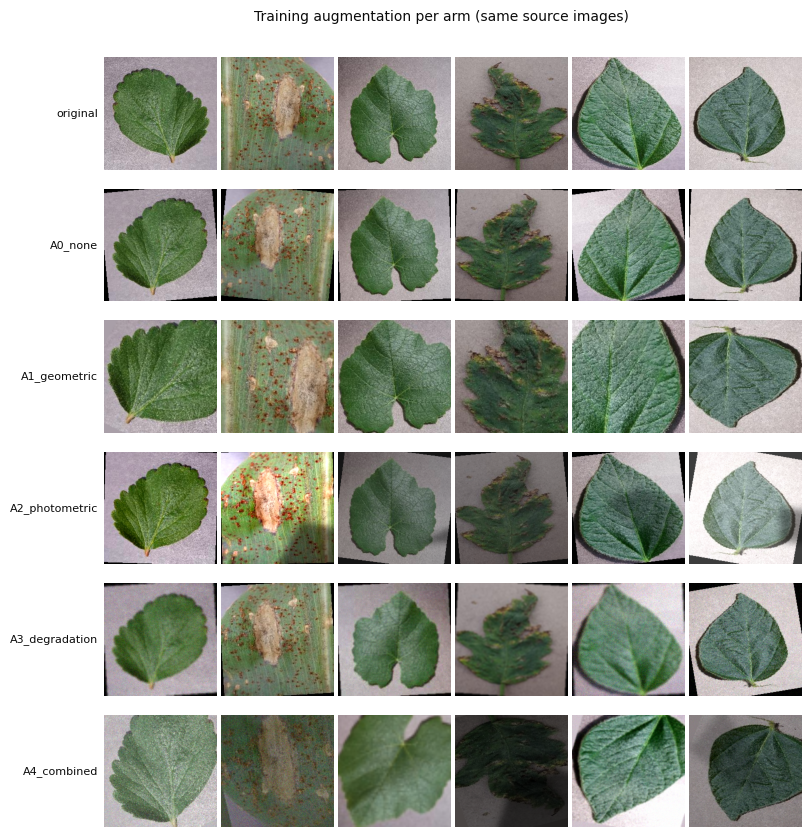

In [18]:
# 5a. Augmentation preview: every arm should look different; only A0, A2 and A3 may show thin black corners
preview_augmentations(cfg, data)

In [19]:
# 5b. Smoke test: proves the training loop works on this machine; its numbers mean nothing
if RUN_SMOKE:
    scfg = make_config(smoke=True, backbone=BACKBONE, **EXTRA)  # one epoch: checks plumbing, not the recipe
    run_sweep(scfg, prepare_data(scfg, verbose=False))


=== run 1/2: A0_none, seed 42 ===
[skip] A0_none__seed42 already done

=== run 2/2: A4_combined, seed 42 ===
[skip] A4_combined__seed42 already done

Sweep finished. Results in /content/drive/Shareddrives/COS 801 Group 6/results/rq72_smoke_aligned


### 6. The sweep
Seeds are the outer loop, so all five arms get seed 1 before any arm gets seed 2. If time runs out, you still have a complete comparison, with less information about seed-to-seed variation. After each run it prints how long the rest will take at the current pace.

In [20]:
# 6. The sweep
run_sweep(cfg, data)


=== run 1/15: A0_none, seed 42 ===
[skip] A0_none__seed42 already done

=== run 2/15: A1_geometric, seed 42 ===
[skip] A1_geometric__seed42 already done

=== run 3/15: A2_photometric, seed 42 ===
[skip] A2_photometric__seed42 already done

=== run 4/15: A3_degradation, seed 42 ===
[skip] A3_degradation__seed42 already done

=== run 5/15: A4_combined, seed 42 ===
[skip] A4_combined__seed42 already done

=== run 6/15: A0_none, seed 43 ===
[skip] A0_none__seed43 already done

=== run 7/15: A1_geometric, seed 43 ===
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 60.4MB/s]


  A1_geometric__seed43  epoch 1/10  loss 0.286  val acc 0.938  val macro-F1 0.926 *  (108s)
  A1_geometric__seed43  epoch 2/10  loss 0.109  val acc 0.930  val macro-F1 0.937  (107s)
  A1_geometric__seed43  epoch 3/10  loss 0.085  val acc 0.927  val macro-F1 0.914  (109s)
  A1_geometric__seed43  epoch 4/10  loss 0.060  val acc 0.979  val macro-F1 0.959 *  (108s)
  A1_geometric__seed43  epoch 5/10  loss 0.043  val acc 0.971  val macro-F1 0.972  (108s)
  A1_geometric__seed43  epoch 6/10  loss 0.033  val acc 0.992  val macro-F1 0.988 *  (107s)
  A1_geometric__seed43  epoch 7/10  loss 0.024  val acc 0.992  val macro-F1 0.990  (108s)
  A1_geometric__seed43  epoch 8/10  loss 0.016  val acc 0.992  val macro-F1 0.991 *  (107s)
  A1_geometric__seed43  epoch 9/10  loss 0.012  val acc 0.996  val macro-F1 0.995 *  (107s)
  A1_geometric__seed43  epoch 10/10  loss 0.009  val acc 0.997  val macro-F1 0.996 *  (106s)
[done] A1_geometric__seed43: lab 0.996  field 0.120  gap 0.876
    this run 18 min | 8 

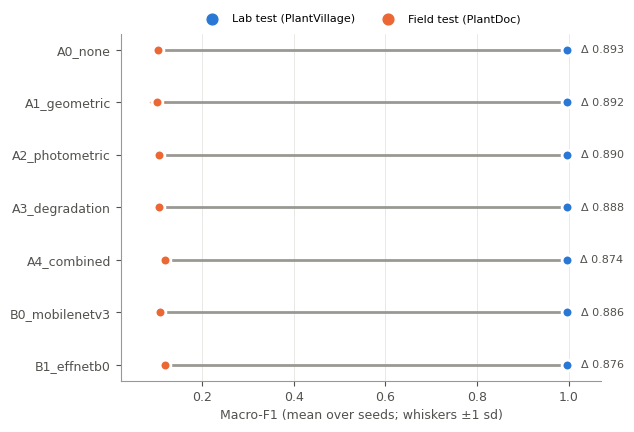

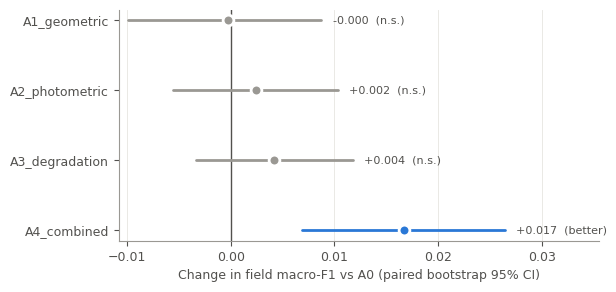

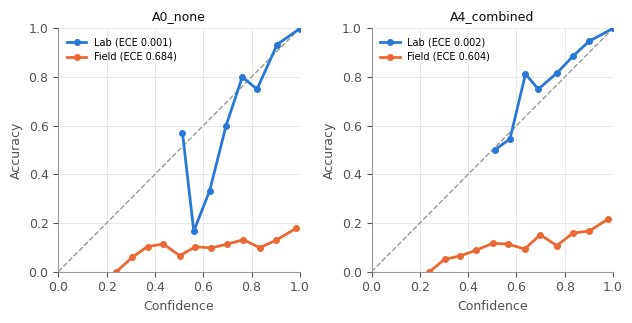

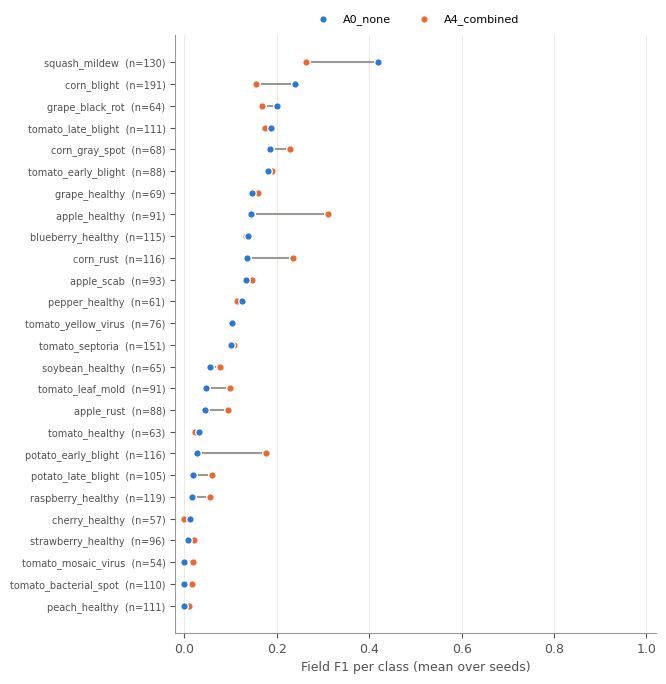

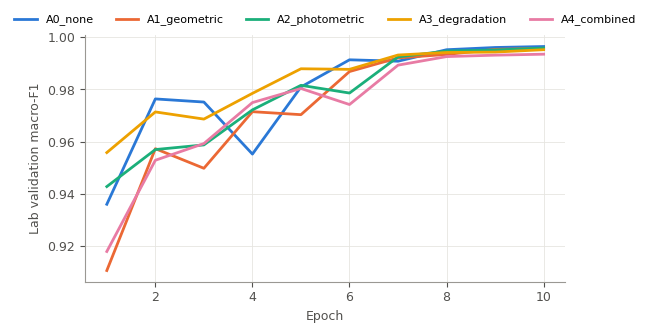

           arm  n_seeds  lab_f1  field_f1   gap  field_gain  field_gain_ci_lo  field_gain_ci_hi  field_gain_p  gap_closed  field_ece
       A0_none        3   0.996     0.104 0.893       0.000             0.000             0.000           NaN       0.000      0.684
  A1_geometric        3   0.996     0.103 0.892      -0.000            -0.010             0.009         0.912      -0.000      0.653
A2_photometric        3   0.996     0.106 0.890       0.002            -0.006             0.010         0.550       0.003      0.657
A3_degradation        3   0.995     0.108 0.888       0.004            -0.003             0.012         0.305       0.005      0.655
   A4_combined        2   0.995     0.120 0.874       0.017             0.007             0.026         0.000       0.019      0.604
B0_mobilenetv3        1   0.995     0.108 0.886       0.005            -0.005             0.015         0.351       0.006      0.636
   B1_effnetb0        1   0.995     0.119 0.876       0.015          

,arm,n_seeds,hypothesis,lab_f1,lab_f1_sd,field_f1,field_f1_sd,gap,gap_sd,gap_ci_lo,...,field_gain_ci_lo,field_gain_ci_hi,field_gain_p,lab_cost_ci_lo,lab_cost_ci_hi,lab_ece,field_ece,lab_acc,field_acc,gap_closed
0,A0_none,3,Control: the group baseline's augmentation (re...,0.996437,0.001101,0.103530,0.002920,0.892907,0.003486,0.883981,...,0.000000,0.000000,NaN,0.000000,0.000000,0.001548,0.683728,0.997520,0.140456,0.000000
1,A1_geometric,3,"Field photos differ in framing, scale, angle a...",0.995565,0.000225,0.103254,0.016862,0.892312,0.016771,0.883056,...,-0.009932,0.008742,0.912,-0.002199,0.000467,0.001539,0.652812,0.996838,0.129518,-0.000310
2,A2_photometric,3,Field photos differ in illumination: colour ca...,0.995704,0.000713,0.105930,0.006682,0.889773,0.006932,0.879833,...,-0.005568,0.010314,0.550,-0.002279,0.000825,0.001650,0.657120,0.997024,0.142057,0.002688
3,A3_degradation,3,Phone cameras lose lesion detail: fewer pixels...,0.995251,0.000825,0.107654,0.005236,0.887597,0.004594,0.877885,...,-0.003382,0.011751,0.305,-0.002789,0.000461,0.001925,0.655257,0.996776,0.149526,0.004619
4,A4_combined,2,The factors are complementary: A1 + A2 + A3 to...,0.994584,0.000451,0.120238,0.003322,0.874346,0.003773,0.863160,...,0.006877,0.026452,0.000,-0.004010,0.000196,0.002110,0.603649,0.996001,0.149860,0.018711
5,B0_mobilenetv3,1,Existing mobilenet_v3_small checkpoint (mobile...,0.994783,NaN,0.108456,NaN,0.886327,NaN,0.875109,...,-0.005004,0.014836,0.351,-0.003840,0.000343,0.001789,0.636005,0.996280,0.158463,0.005517
6,B1_effnetb0,1,Existing efficientnet_b0 checkpoint (effnetb0_...,0.994619,NaN,0.118905,NaN,0.875714,NaN,0.864034,...,0.004644,0.026272,0.002,-0.004217,0.000582,0.001572,0.575277,0.996280,0.170468,0.017219


In [21]:
# 7. Analysis: tables, figures and the headline sentence for report section 5
table = analyse(cfg, data)
table